In [ ]:
# ============================================================
# CELL 1A: UPLOAD THE TWO RESEARCH DATASETS
# TASK: Upload hallucination dataset and knowledge base
# ============================================================

from google.colab import files
import json
import pandas as pd

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving amharic_hallucination_dataset.json to amharic_hallucination_dataset.json
Saving knowledge_base.csv to knowledge_base.csv

Uploaded files:
amharic_hallucination_dataset.json
knowledge_base.csv


In [ ]:
# ============================================================
# CELL 1: IMPORT LIBRARIES AND LOAD BOTH DATASETS
# TASK: Load the Amharic hallucination dataset and knowledge base
# ============================================================

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load hallucination dataset
with open("/content/amharic_hallucination_dataset.json",
          "r", encoding="utf-8") as f:
    df = pd.DataFrame(json.load(f))

# Load knowledge base dataset
knowledge_base = pd.read_csv(
    "/content/knowledge_base.csv",
    encoding="utf-8"
)

# Display dataset information
print("HALLUCINATION DATASET")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

print("\nKNOWLEDGE BASE DATASET")
print("Shape:", knowledge_base.shape)
print("Columns:", knowledge_base.columns.tolist())
display(knowledge_base.head())

HALLUCINATION DATASET
Shape: (4115, 4)
Columns: ['id', 'question', 'answer', 'label']


,id,question,answer,label
0,1,ኢትዮጵያ በየትኛው አህጉር ላይ ትገኛለች?,ኢትዮጵያ በአውስትራሊያ ትገኛለች።,1
1,2,ሃይለ ሥላሴ ማን ነበር?,ሃይለ ሥላሴ የናይጄሪያ መሪ ነበር።,1
2,3,በኢትዮጵያ ሙስሊሞች አሉ ወይ?,አይደለም፣ ኢትዮጵያ ሙሉ በሙሉ ክርስቲያን ናት።,1
3,4,ኢትዮጵያ የገንዘብ አሃድ ምን ይባላል?,ኢትዮጵያ የገንዘብ አሃድ ዶላር ይባላል።,1
4,5,ሃይለ ሥላሴ ማን ነበር?,ሃይለ ሥላሴ የኢትዮጵያ ንጉሠ ነገሥት ነበር።,0



KNOWLEDGE BASE DATASET
Shape: (5120, 3)
Columns: ['subject', 'relation', 'object']


,subject,relation,object
0,ኢትዮጵያ,located_in,አፍሪካ
1,ኢትዮጵያ,capital,አዲስ አበባ
2,አዲስ አበባ,country,ኢትዮጵያ
3,አዲስ አበባ,is_capital_of,ኢትዮጵያ
4,አቢይ አህመድ,position,ጠቅላይ ሚኒስትር


In [ ]:
# ============================================================
# CELL 1B: LOAD BOTH UPLOADED DATASETS
# TASK: Load the labelled hallucination dataset and knowledge base
# ============================================================

import json
import pandas as pd

json_files = [f for f in uploaded if f.lower().endswith(".json")]
csv_files = [f for f in uploaded if f.lower().endswith(".csv")]

if len(json_files) != 1 or len(csv_files) != 1:
    raise ValueError(
        f"Expected one JSON and one CSV file. "
        f"Found JSON: {json_files}, CSV: {csv_files}"
    )

with open(json_files[0], "r", encoding="utf-8") as f:
    df = pd.DataFrame(json.load(f))

knowledge_base = pd.read_csv(csv_files[0], encoding="utf-8")

print("Hallucination dataset:", df.shape)
print("Knowledge base:", knowledge_base.shape)
print("\nDataset columns:", df.columns.tolist())
print("Knowledge base columns:", knowledge_base.columns.tolist())

Hallucination dataset: (4115, 4)
Knowledge base: (5120, 3)

Dataset columns: ['id', 'question', 'answer', 'label']
Knowledge base columns: ['subject', 'relation', 'object']


In [ ]:
# ============================================================
# CELL 2: INSPECT DATASET STRUCTURE AND QUALITY
# TASK: Check required columns, missing values, labels, and samples
# ============================================================

print("HALLUCINATION DATASET")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nLabel distribution:")
print(df["label"].value_counts(dropna=False))
print("\nSample records:")
display(df.head(3))

print("\nKNOWLEDGE BASE")
print("Shape:", knowledge_base.shape)
print("Columns:", knowledge_base.columns.tolist())
print("\nMissing values:")
print(knowledge_base.isnull().sum())
print("\nSample triples:")
display(knowledge_base.head(3))

HALLUCINATION DATASET
Shape: (4115, 4)
Columns: ['id', 'question', 'answer', 'label']

Missing values:
id          0
question    0
answer      0
label       0
dtype: int64

Label distribution:
label
1    3078
0    1037
Name: count, dtype: int64

Sample records:


,id,question,answer,label
0,1,ኢትዮጵያ በየትኛው አህጉር ላይ ትገኛለች?,ኢትዮጵያ በአውስትራሊያ ትገኛለች።,1
1,2,ሃይለ ሥላሴ ማን ነበር?,ሃይለ ሥላሴ የናይጄሪያ መሪ ነበር።,1
2,3,በኢትዮጵያ ሙስሊሞች አሉ ወይ?,አይደለም፣ ኢትዮጵያ ሙሉ በሙሉ ክርስቲያን ናት።,1



KNOWLEDGE BASE
Shape: (5120, 3)
Columns: ['subject', 'relation', 'object']

Missing values:
subject     0
relation    0
object      0
dtype: int64

Sample triples:


,subject,relation,object
0,ኢትዮጵያ,located_in,አፍሪካ
1,ኢትዮጵያ,capital,አዲስ አበባ
2,አዲስ አበባ,country,ኢትዮጵያ


In [ ]:
# ============================================================
# CELL 3: VALIDATE DATASET BEFORE TRAIN-VALIDATION-TEST SPLIT
# TASK: Check required columns, labels, and repeated questions
# ============================================================

required_columns = ["question", "answer", "label"]
kb_columns = ["subject", "relation", "object"]

assert all(col in df.columns for col in required_columns), \
    "Hallucination dataset is missing required columns."

assert all(col in knowledge_base.columns for col in kb_columns), \
    "Knowledge base is missing required columns."

assert df[required_columns].notna().all().all(), \
    "Missing values found in required dataset columns."

assert set(df["label"].unique()).issubset({0, 1}), \
    "Labels must be 0 (Non-Hallucinated) or 1 (Hallucinated)."

print("Dataset validation successful.")
print("Total records:", len(df))
print("Unique questions:", df["question"].nunique())
print("Repeated question records:", df["question"].duplicated().sum())
print("\nClass distribution:")
print(df["label"].value_counts().sort_index())

Dataset validation successful.
Total records: 4115
Unique questions: 68
Repeated question records: 4047

Class distribution:
label
0    1037
1    3078
Name: count, dtype: int64


In [ ]:
# ============================================================
# CELL 4: GROUPED TRAIN-VALIDATION-TEST SPLIT
# TASK: Split dataset into 70% training, 15% validation, 15% testing
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# First split: 70% training and 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(df, groups=df["question"])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# Second split: divide remaining 30% equally
split2 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df["question"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("TRAINING:", len(train_df), f"({len(train_df)/len(df)*100:.2f}%)")
print("VALIDATION:", len(val_df), f"({len(val_df)/len(df)*100:.2f}%)")
print("TESTING:", len(test_df), f"({len(test_df)/len(df)*100:.2f}%)")
print("TOTAL:", len(train_df) + len(val_df) + len(test_df))

TRAINING: 2794 (67.90%)
VALIDATION: 585 (14.22%)
TESTING: 736 (17.89%)
TOTAL: 4115


In [ ]:
# ============================================================
# CELL 5: VERIFY TRAINING, VALIDATION AND TESTING SPLITS
# TASK: Check split sizes, class distributions, and question leakage
# ============================================================

for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}:")
    print("Records:", len(part))
    print("Percentage:", round(len(part) / len(df) * 100, 2), "%")
    print("Class distribution:")
    print(part["label"].value_counts().sort_index())

train_questions = set(train_df["question"])
val_questions = set(val_df["question"])
test_questions = set(test_df["question"])

print("\nQuestion leakage check:")
print("Train vs Validation:", len(train_questions & val_questions))
print("Train vs Test:", len(train_questions & test_questions))
print("Validation vs Test:", len(val_questions & test_questions))

assert not (train_questions & val_questions)
assert not (train_questions & test_questions)
assert not (val_questions & test_questions)

print("\nAll split checks passed.")


Training:
Records: 2794
Percentage: 67.9 %
Class distribution:
label
0     716
1    2078
Name: count, dtype: int64

Validation:
Records: 585
Percentage: 14.22 %
Class distribution:
label
0    153
1    432
Name: count, dtype: int64

Testing:
Records: 736
Percentage: 17.89 %
Class distribution:
label
0    168
1    568
Name: count, dtype: int64

Question leakage check:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

All split checks passed.


In [ ]:
# ============================================================
# CELL 6: PREPARE TRAINING, VALIDATION AND TEST DATA
# TASK: Combine questions and answers and extract binary labels
# ============================================================

# Combine question and answer
train_text = (
    train_df["question"].astype(str) + " " +
    train_df["answer"].astype(str)
).tolist()

val_text = (
    val_df["question"].astype(str) + " " +
    val_df["answer"].astype(str)
).tolist()

test_text = (
    test_df["question"].astype(str) + " " +
    test_df["answer"].astype(str)
).tolist()

# Extract labels
y_train = train_df["label"].astype(int).to_numpy()
y_val = val_df["label"].astype(int).to_numpy()
y_test = test_df["label"].astype(int).to_numpy()

print("Training samples:", len(train_text))
print("Validation samples:", len(val_text))
print("Testing samples:", len(test_text))

print("\nExample training text:")
print(train_text[0])

print("\nExample label:", y_train[0])

Training samples: 2794
Validation samples: 585
Testing samples: 736

Example training text:
ኢትዮጵያ የገንዘብ አሃድ ምን ይባላል? ኢትዮጵያ የገንዘብ አሃድ ዶላር ይባላል።

Example label: 1


In [ ]:
# ============================================================
# CELL 7: CLEAN AND PREPARE KNOWLEDGE BASE
# TASK: Prepare subject-relation-object triples for retrieval
# ============================================================

# Remove incomplete triples
knowledge_base = knowledge_base.dropna(
    subset=["subject", "relation", "object"]
).copy()

# Convert triple components to strings
for col in ["subject", "relation", "object"]:
    knowledge_base[col] = knowledge_base[col].astype(str).str.strip()

# Remove empty records and duplicate triples
knowledge_base = knowledge_base[
    (knowledge_base["subject"] != "") &
    (knowledge_base["relation"] != "") &
    (knowledge_base["object"] != "")
].drop_duplicates(
    subset=["subject", "relation", "object"]
).reset_index(drop=True)

# Combine triples
knowledge_base["triple"] = (
    knowledge_base["subject"] + " " +
    knowledge_base["relation"] + " " +
    knowledge_base["object"]
)

print("Knowledge base prepared successfully.")
print("Total valid triples:", len(knowledge_base))
print("\nSample knowledge triples:")
display(knowledge_base[["subject", "relation", "object", "triple"]].head())

Knowledge base prepared successfully.
Total valid triples: 5120

Sample knowledge triples:


,subject,relation,object,triple
0,ኢትዮጵያ,located_in,አፍሪካ,ኢትዮጵያ located_in አፍሪካ
1,ኢትዮጵያ,capital,አዲስ አበባ,ኢትዮጵያ capital አዲስ አበባ
2,አዲስ አበባ,country,ኢትዮጵያ,አዲስ አበባ country ኢትዮጵያ
3,አዲስ አበባ,is_capital_of,ኢትዮጵያ,አዲስ አበባ is_capital_of ኢትዮጵያ
4,አቢይ አህመድ,position,ጠቅላይ ሚኒስትር,አቢይ አህመድ position ጠቅላይ ሚኒስትር


In [ ]:
# ============================================================
# CELL 8: BUILD KNOWLEDGE BASE RETRIEVAL INDEX
# TASK: Retrieve relevant knowledge triples using cosine similarity
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

# Convert knowledge triples into TF-IDF vectors
kb_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    max_features=100000
)

kb_matrix = kb_vectorizer.fit_transform(
    knowledge_base["triple"]
)

# Build cosine similarity retrieval index
n_neighbors = min(3, len(knowledge_base))

kb_retriever = NearestNeighbors(
    n_neighbors=n_neighbors,
    metric="cosine",
    algorithm="brute"
)

kb_retriever.fit(kb_matrix)

print("Knowledge retrieval system ready.")
print("Knowledge triples:", kb_matrix.shape[0])
print("TF-IDF features:", kb_matrix.shape[1])
print("Top retrieved triples:", n_neighbors)

Knowledge retrieval system ready.
Knowledge triples: 5120
TF-IDF features: 22304
Top retrieved triples: 3


In [ ]:
# ============================================================
# CELL 9: EXTRACT KNOWLEDGE BASE FEATURES
# TASK: Calculate question and answer similarity with retrieved triples
# ============================================================

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def extract_kb_features(data):

    questions = kb_vectorizer.transform(
        data["question"].astype(str)
    )

    answers = kb_vectorizer.transform(
        data["answer"].astype(str)
    )

    distances, indices = kb_retriever.kneighbors(questions)

    features = []

    for i, idx in enumerate(indices):

        triple_vectors = kb_matrix[idx]

        # Answer similarity with retrieved triples
        answer_sim = cosine_similarity(
            answers[i], triple_vectors
        ).ravel()

        # Answer similarity with retrieved objects
        objects = knowledge_base.iloc[idx]["object"].tolist()
        object_vectors = kb_vectorizer.transform(objects)

        object_sim = cosine_similarity(
            answers[i], object_vectors
        ).ravel()

        # Convert cosine distances into similarities
        question_sim = 1 - distances[i]

        features.append([
            question_sim.max(),
            question_sim.mean(),
            answer_sim.max(),
            object_sim.max()
        ])

    return np.asarray(features, dtype=np.float32)


print("Knowledge feature extraction function defined.")
print("Features: question max similarity, question mean similarity,")
print("answer-triple similarity, answer-object similarity.")

Knowledge feature extraction function defined.
Features: question max similarity, question mean similarity,
answer-triple similarity, answer-object similarity.


In [ ]:
# ============================================================
# CELL 10: GENERATE KNOWLEDGE BASE FEATURES
# TASK: Extract four KB features for training, validation and testing
# ============================================================

X_train_kb = extract_kb_features(train_df)
X_val_kb = extract_kb_features(val_df)
X_test_kb = extract_kb_features(test_df)

print("Training KB features:", X_train_kb.shape)
print("Validation KB features:", X_val_kb.shape)
print("Testing KB features:", X_test_kb.shape)

print("\nSample KB features:")
print(X_train_kb[:3])

assert X_train_kb.shape[1] == 4
assert X_val_kb.shape[1] == 4
assert X_test_kb.shape[1] == 4

print("\nKnowledge Base features extracted successfully.")

Training KB features: (2794, 4)
Validation KB features: (585, 4)
Testing KB features: (736, 4)

Sample KB features:
[[0.22162539 0.2039064  0.2390494  0.46162474]
 [0.35682335 0.29050633 0.19049712 0.        ]
 [0.290355   0.2512291  0.16652127 0.15250896]]

Knowledge Base features extracted successfully.


In [ ]:
# ============================================================
# CELL 11: IMPORT MODELING AND EVALUATION LIBRARIES
# TASK: Prepare libraries for SVM, BiLSTM, mBERT and hybrid models
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nModeling and evaluation libraries imported successfully.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4

Modeling and evaluation libraries imported successfully.


In [ ]:
# ============================================================
# CELL 12: TRAIN TF-IDF + SVM
# TASK: Train the first baseline hallucination detection model
# ============================================================

from sklearn.pipeline import Pipeline

svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        max_features=100000,
        sublinear_tf=True
    )),
    ("svm", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

# Train using training data only
svm_model.fit(train_text, y_train)

# Validation prediction
svm_val_pred = svm_model.predict(val_text)

print("TF-IDF + SVM training completed.")
print("Validation accuracy:",
      round(accuracy_score(y_val, svm_val_pred), 4))
print("\nValidation classification report:")
print(classification_report(
    y_val,
    svm_val_pred,
    target_names=["Non-Hallucinated", "Hallucinated"],
    zero_division=0
))

TF-IDF + SVM training completed.
Validation accuracy: 0.7368

Validation classification report:
                  precision    recall  f1-score   support

Non-Hallucinated       0.50      0.90      0.64       153
    Hallucinated       0.95      0.68      0.79       432

        accuracy                           0.74       585
       macro avg       0.72      0.79      0.72       585
    weighted avg       0.83      0.74      0.75       585



TF-IDF + SVM TEST PERFORMANCE
Accuracy: 0.8573
Precision: 0.8015
Recall: 0.7818
Macro F1: 0.7908
Weighted F1: 0.8549

Class-wise classification report:
                  precision    recall  f1-score   support

Non-Hallucinated       0.71      0.64      0.67       168
    Hallucinated       0.90      0.92      0.91       568

        accuracy                           0.86       736
       macro avg       0.80      0.78      0.79       736
    weighted avg       0.85      0.86      0.85       736



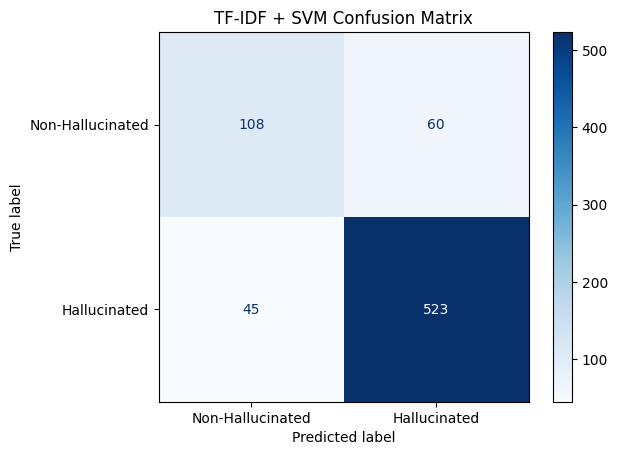

In [ ]:
# ============================================================
# CELL 13: TEST TF-IDF + SVM
# TASK: Calculate final test metrics and confusion matrix
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

svm_test_pred = svm_model.predict(test_text)

print("TF-IDF + SVM TEST PERFORMANCE")
print("=" * 50)

print("Accuracy:", round(accuracy_score(y_test, svm_test_pred), 4))
print("Precision:", round(precision_score(y_test, svm_test_pred, average="macro", zero_division=0), 4))
print("Recall:", round(recall_score(y_test, svm_test_pred, average="macro", zero_division=0), 4))
print("Macro F1:", round(f1_score(y_test, svm_test_pred, average="macro", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_test, svm_test_pred, average="weighted", zero_division=0), 4))

print("\nClass-wise classification report:")
print(classification_report(
    y_test,
    svm_test_pred,
    target_names=["Non-Hallucinated", "Hallucinated"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_test_pred,
    display_labels=["Non-Hallucinated", "Hallucinated"],
    cmap="Blues",
    values_format="d"
)

plt.title("TF-IDF + SVM Confusion Matrix")
plt.show()

In [ ]:
# ============================================================
# CELL 14: TOKENIZE DATA FOR BiLSTM
# TASK: Build vocabulary and prepare padded sequences
# ============================================================

import re
from collections import Counter
from torch.utils.data import TensorDataset, DataLoader

MAX_VOCAB = 30000
MAX_LEN = 128
BATCH_SIZE = 32

# Tokenize Amharic and other text
def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", str(text).lower())

# Build vocabulary from training text only
word_counts = Counter(
    token
    for text in train_text
    for token in tokenize(text)
)

vocab = {"<PAD>": 0, "<UNK>": 1}

for word, count in word_counts.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

# Convert text into padded sequences
def encode_texts(texts):
    sequences = []
    for text in texts:
        ids = [vocab.get(token, 1) for token in tokenize(text)]
        ids = ids[:MAX_LEN]
        ids += [0] * (MAX_LEN - len(ids))
        sequences.append(ids)
    return torch.tensor(sequences, dtype=torch.long)

X_train_bilstm = encode_texts(train_text)
X_val_bilstm = encode_texts(val_text)
X_test_bilstm = encode_texts(test_text)

# Create data loaders
train_dataset = TensorDataset(
    X_train_bilstm, torch.tensor(y_train, dtype=torch.long)
)
val_dataset = TensorDataset(
    X_val_bilstm, torch.tensor(y_val, dtype=torch.long)
)
test_dataset = TensorDataset(
    X_test_bilstm, torch.tensor(y_test, dtype=torch.long)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

print("Vocabulary size:", len(vocab))
print("Training sequences:", X_train_bilstm.shape)
print("Validation sequences:", X_val_bilstm.shape)
print("Testing sequences:", X_test_bilstm.shape)
print("Maximum sequence length:", MAX_LEN)

Vocabulary size: 231
Training sequences: torch.Size([2794, 128])
Validation sequences: torch.Size([585, 128])
Testing sequences: torch.Size([736, 128])
Maximum sequence length: 128


In [ ]:
# ============================================================
# MODEL 2: BiLSTM
# CELL 1: TOKENIZATION AND VOCABULARY PREPARATION
# TASK: Build vocabulary using training data only
# ============================================================

import re
from collections import Counter
from torch.utils.data import TensorDataset, DataLoader

MAX_VOCAB = 30000
MAX_LEN = 128
BATCH_SIZE = 32

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", str(text).lower())

# Build vocabulary from training text only
word_counts = Counter(
    token
    for text in train_text
    for token in tokenize(text)
)

vocab = {"<PAD>": 0, "<UNK>": 1}

for word, count in word_counts.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode_texts(texts):
    sequences = []
    for text in texts:
        ids = [vocab.get(token, 1) for token in tokenize(text)]
        ids = ids[:MAX_LEN]
        ids += [0] * (MAX_LEN - len(ids))
        sequences.append(ids)
    return torch.tensor(sequences, dtype=torch.long)

X_train_bilstm = encode_texts(train_text)
X_val_bilstm = encode_texts(val_text)
X_test_bilstm = encode_texts(test_text)

print("Vocabulary size:", len(vocab))
print("Training:", X_train_bilstm.shape)
print("Validation:", X_val_bilstm.shape)
print("Testing:", X_test_bilstm.shape)

Vocabulary size: 231
Training: torch.Size([2794, 128])
Validation: torch.Size([585, 128])
Testing: torch.Size([736, 128])


In [ ]:
# ============================================================
# MODEL 2: BiLSTM
# CELL 2: CREATE DATA LOADERS
# TASK: Prepare training, validation and testing batches
# ============================================================

from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 32

train_dataset = TensorDataset(
    X_train_bilstm,
    torch.tensor(y_train, dtype=torch.long)
)

val_dataset = TensorDataset(
    X_val_bilstm,
    torch.tensor(y_val, dtype=torch.long)
)

test_dataset = TensorDataset(
    X_test_bilstm,
    torch.tensor(y_test, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 88
Validation batches: 19
Testing batches: 23


In [ ]:
# ============================================================
# MODEL 2: BiLSTM
# CELL 3: DEFINE BiLSTM ARCHITECTURE
# TASK: Build a bidirectional LSTM binary classifier
# ============================================================

import torch
import torch.nn as nn

class BiLSTMClassifier(nn.Module):

    def __init__(self, vocab_size, embedding_dim=128,
                 hidden_dim=128, num_classes=2):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)

        features = torch.cat(
            (hidden[-2], hidden[-1]), dim=1
        )

        return self.fc(self.dropout(features))


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

bilstm_model = BiLSTMClassifier(
    vocab_size=len(vocab)
).to(device)

print(bilstm_model)
print("\nDevice:", device)

BiLSTMClassifier(
  (embedding): Embedding(231, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=2, bias=True)
)

Device: cuda


In [ ]:
# ============================================================
# MODEL 2: BiLSTM
# CELL 4: CONFIGURE LOSS AND OPTIMIZER
# TASK: Set class-weighted loss and Adam optimizer
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = torch.tensor(
    weights, dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = optim.Adam(
    bilstm_model.parameters(),
    lr=0.001
)

print("Class weights:", weights)
print("Learning rate: 0.001")
print("Optimizer: Adam")
print("Loss function: Weighted CrossEntropyLoss")

Class weights: [1.95111732 0.67228104]
Learning rate: 0.001
Optimizer: Adam
Loss function: Weighted CrossEntropyLoss


In [ ]:
# ============================================================
# MODEL 2: BiLSTM
# CELL 5: TRAIN BiLSTM FOR 10 EPOCHS
# TASK: Train model and monitor validation performance
# ============================================================

EPOCHS = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(EPOCHS):

    bilstm_model.train()
    train_loss, train_correct, train_total = 0, 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = bilstm_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    bilstm_model.eval()
    val_loss, val_correct, val_total = 0, 0, 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = bilstm_model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    history["train_loss"].append(train_loss / train_total)
    history["val_loss"].append(val_loss / val_total)
    history["train_acc"].append(train_correct / train_total)
    history["val_acc"].append(val_correct / val_total)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {history['train_loss'][-1]:.4f} | "
        f"Train Acc: {history['train_acc'][-1]:.4f} | "
        f"Val Loss: {history['val_loss'][-1]:.4f} | "
        f"Val Acc: {history['val_acc'][-1]:.4f}"
    )

Epoch 1/10 | Train Loss: 0.6530 | Train Acc: 0.6077 | Val Loss: 0.5291 | Val Acc: 0.5761
Epoch 2/10 | Train Loss: 0.1019 | Train Acc: 0.9538 | Val Loss: 0.7586 | Val Acc: 0.7624
Epoch 3/10 | Train Loss: 0.0772 | Train Acc: 0.9821 | Val Loss: 1.2082 | Val Acc: 0.6547
Epoch 4/10 | Train Loss: 0.0019 | Train Acc: 1.0000 | Val Loss: 1.3954 | Val Acc: 0.6547
Epoch 5/10 | Train Loss: 0.0010 | Train Acc: 1.0000 | Val Loss: 1.5798 | Val Acc: 0.6547
Epoch 6/10 | Train Loss: 0.0006 | Train Acc: 1.0000 | Val Loss: 1.7038 | Val Acc: 0.6547
Epoch 7/10 | Train Loss: 0.0004 | Train Acc: 1.0000 | Val Loss: 1.7710 | Val Acc: 0.6547
Epoch 8/10 | Train Loss: 0.0003 | Train Acc: 1.0000 | Val Loss: 1.8134 | Val Acc: 0.6547
Epoch 9/10 | Train Loss: 0.0002 | Train Acc: 1.0000 | Val Loss: 1.8688 | Val Acc: 0.6547
Epoch 10/10 | Train Loss: 0.0002 | Train Acc: 1.0000 | Val Loss: 1.9326 | Val Acc: 0.6530


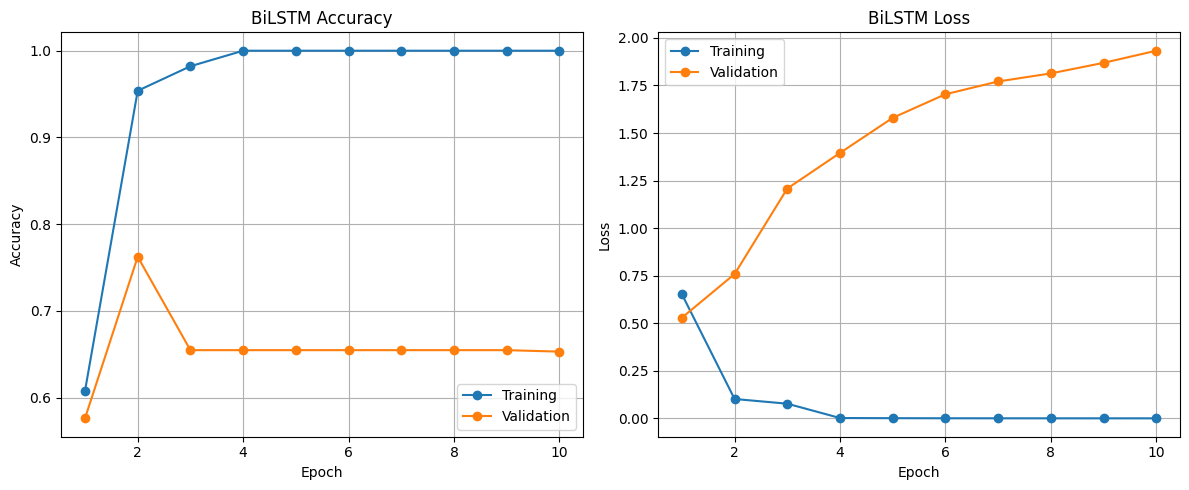

In [ ]:
# ============================================================
# MODEL 2: BiLSTM
# CELL 6: PLOT TRAINING CURVES
# TASK: Visualize accuracy and loss across 10 epochs
# ============================================================

import matplotlib.pyplot as plt

epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_acc"], marker="o", label="Training")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation")
plt.title("BiLSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_loss"], marker="o", label="Training")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation")
plt.title("BiLSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

BiLSTM TEST PERFORMANCE
Accuracy: 0.8967
Macro Precision: 0.8478
Macro Recall: 0.8702
Macro F1: 0.8581
Weighted F1: 0.8983

Class-wise report:
                  precision    recall  f1-score   support

Non-Hallucinated       0.75      0.82      0.78       168
    Hallucinated       0.95      0.92      0.93       568

        accuracy                           0.90       736
       macro avg       0.85      0.87      0.86       736
    weighted avg       0.90      0.90      0.90       736



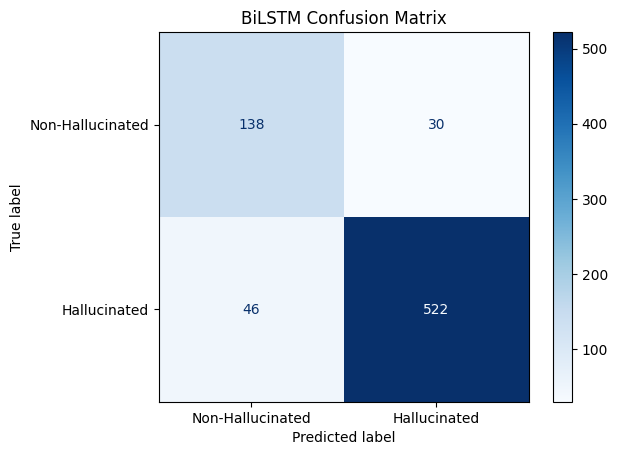

In [ ]:
# ============================================================
# MODEL 2: BiLSTM
# CELL 7: FINAL TEST EVALUATION
# TASK: Calculate classification metrics and confusion matrix
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, ConfusionMatrixDisplay
)

bilstm_model.eval()
bilstm_test_pred = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = bilstm_model(inputs)
        bilstm_test_pred.extend(outputs.argmax(1).cpu().numpy())

print("BiLSTM TEST PERFORMANCE")
print("=" * 50)

print("Accuracy:", round(accuracy_score(y_test, bilstm_test_pred), 4))
print("Macro Precision:", round(precision_score(y_test, bilstm_test_pred, average="macro", zero_division=0), 4))
print("Macro Recall:", round(recall_score(y_test, bilstm_test_pred, average="macro", zero_division=0), 4))
print("Macro F1:", round(f1_score(y_test, bilstm_test_pred, average="macro", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_test, bilstm_test_pred, average="weighted", zero_division=0), 4))

print("\nClass-wise report:")
print(classification_report(
    y_test,
    bilstm_test_pred,
    target_names=["Non-Hallucinated", "Hallucinated"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    bilstm_test_pred,
    display_labels=["Non-Hallucinated", "Hallucinated"],
    cmap="Blues",
    values_format="d"
)
plt.title("BiLSTM Confusion Matrix")
plt.show()

BiLSTM TEST PERFORMANCE
Accuracy: 0.8967
Macro Precision: 0.8478
Macro Recall: 0.8702
Macro F1: 0.8581
Weighted F1: 0.8983

CLASS-WISE PERFORMANCE REPORT
                  precision    recall  f1-score   support

Non-Hallucinated     0.7500    0.8214    0.7841       168
    Hallucinated     0.9457    0.9190    0.9321       568

        accuracy                         0.8967       736
       macro avg     0.8478    0.8702    0.8581       736
    weighted avg     0.9010    0.8967    0.8983       736



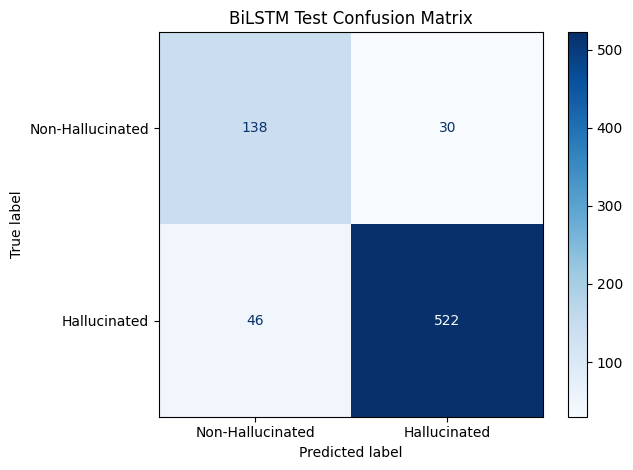

In [ ]:
# ============================================================
# MODEL 2: BiLSTM
# CELL 1: CLASS-WISE PERFORMANCE AND TEST EVALUATION
# TASK: Evaluate BiLSTM using the independent test dataset
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

bilstm_model.eval()

bilstm_test_true = []
bilstm_test_pred = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = bilstm_model(inputs)

        predictions = torch.argmax(outputs, dim=1)

        bilstm_test_pred.extend(predictions.cpu().numpy())
        bilstm_test_true.extend(labels.numpy())

# Overall performance
print("BiLSTM TEST PERFORMANCE")
print("=" * 55)

print("Accuracy:",
      round(accuracy_score(bilstm_test_true, bilstm_test_pred), 4))

print("Macro Precision:",
      round(precision_score(
          bilstm_test_true, bilstm_test_pred,
          average="macro", zero_division=0), 4))

print("Macro Recall:",
      round(recall_score(
          bilstm_test_true, bilstm_test_pred,
          average="macro", zero_division=0), 4))

print("Macro F1:",
      round(f1_score(
          bilstm_test_true, bilstm_test_pred,
          average="macro", zero_division=0), 4))

print("Weighted F1:",
      round(f1_score(
          bilstm_test_true, bilstm_test_pred,
          average="weighted", zero_division=0), 4))

# Class-wise report
print("\nCLASS-WISE PERFORMANCE REPORT")
print(classification_report(
    bilstm_test_true,
    bilstm_test_pred,
    labels=[0, 1],
    target_names=["Non-Hallucinated", "Hallucinated"],
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    bilstm_test_true,
    bilstm_test_pred,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Hallucinated", "Hallucinated"]
).plot(cmap="Blues", values_format="d")

plt.title("BiLSTM Test Confusion Matrix")
plt.tight_layout()
plt.show()

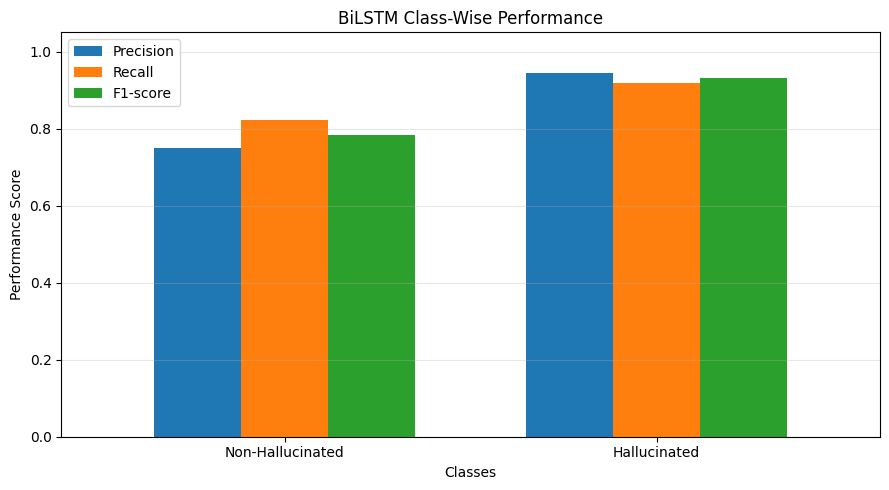

                  precision  recall  f1-score
Non-Hallucinated     0.7500  0.8214    0.7841
Hallucinated         0.9457  0.9190    0.9321


In [ ]:
# ============================================================
# MODEL 2: BiLSTM
# CELL 2: CLASS-WISE PERFORMANCE GRAPH
# TASK: Visualize precision, recall and F1-score by class
# ============================================================

from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

report = classification_report(
    bilstm_test_true,
    bilstm_test_pred,
    labels=[0, 1],
    target_names=["Non-Hallucinated", "Hallucinated"],
    output_dict=True,
    zero_division=0
)

classwise_df = pd.DataFrame(
    report
).T.loc[
    ["Non-Hallucinated", "Hallucinated"],
    ["precision", "recall", "f1-score"]
]

ax = classwise_df.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1.05),
    width=0.7
)

ax.set_title("BiLSTM Class-Wise Performance")
ax.set_xlabel("Classes")
ax.set_ylabel("Performance Score")
ax.set_xticklabels(
    classwise_df.index,
    rotation=0
)
ax.legend(["Precision", "Recall", "F1-score"])
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/content/bilstm_classwise_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(classwise_df.round(4))

In [ ]:
# ============================================================
# MODEL 2: BiLSTM
# CELL 3: TESTING AND PREDICTION
# TASK: Predict hallucination labels for new Amharic sentences
# ============================================================

import re
import torch
import torch.nn.functional as F

def predict_hallucination(question, answer):

    text = str(question) + " " + str(answer)

    tokens = re.findall(r"\w+|[^\w\s]", text.lower())

    token_ids = [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens
    ]

    token_ids = token_ids[:MAX_LEN]

    token_ids += [vocab["<PAD>"]] * (
        MAX_LEN - len(token_ids)
    )

    input_tensor = torch.tensor(
        [token_ids],
        dtype=torch.long
    ).to(device)

    bilstm_model.eval()

    with torch.no_grad():
        logits = bilstm_model(input_tensor)
        probabilities = F.softmax(logits, dim=1)

    predicted_class = torch.argmax(probabilities, dim=1).item()
    confidence = probabilities[0, predicted_class].item() * 100

    label = (
        "Hallucinated"
        if predicted_class == 1
        else "Non-Hallucinated"
    )

    return label, confidence


# Enter new Amharic question-answer examples
test_examples = [
    {
        "Question": "የኢትዮጵያ ዋና ከተማ የት ናት?",
        "Answer": "የኢትዮጵያ ዋና ከተማ አዲስ አበባ ናት።"
    },
    {
        "Question": "የኢትዮጵያ ዋና ከተማ የት ናት?",
        "Answer": "የኢትዮጵያ ዋና ከተማ ናይሮቢ ናት።"
    }
]

prediction_results = []

for example in test_examples:

    prediction, confidence = predict_hallucination(
        example["Question"],
        example["Answer"]
    )

    prediction_results.append({
        "Question": example["Question"],
        "Answer": example["Answer"],
        "Predicted_Label": prediction,
        "Confidence_Percentage": round(confidence, 2)
    })

prediction_df = pd.DataFrame(prediction_results)

display(prediction_df)

,Question,Answer,Predicted_Label,Confidence_Percentage
0,የኢትዮጵያ ዋና ከተማ የት ናት?,የኢትዮጵያ ዋና ከተማ አዲስ አበባ ናት።,Non-Hallucinated,99.99
1,የኢትዮጵያ ዋና ከተማ የት ናት?,የኢትዮጵያ ዋና ከተማ ናይሮቢ ናት።,Hallucinated,99.99


In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 1: INSTALL AND IMPORT TRANSFORMER LIBRARIES
# TASK: Prepare multilingual BERT for hallucination detection
# ============================================================

!pip install -q transformers accelerate

import torch
import numpy as np
import matplotlib.pyplot as plt

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("mBERT libraries imported successfully.")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
mBERT libraries imported successfully.


In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 2: LOAD MULTILINGUAL BERT TOKENIZER
# TASK: Tokenize Amharic question-answer text
# ============================================================

MODEL_NAME = "bert-base-multilingual-cased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(
    train_text,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

val_encodings = tokenizer(
    val_text,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

test_encodings = tokenizer(
    test_text,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

print("mBERT tokenizer loaded successfully.")
print("Training samples:", len(train_encodings["input_ids"]))
print("Validation samples:", len(val_encodings["input_ids"]))
print("Testing samples:", len(test_encodings["input_ids"]))
print("Maximum token length:", MAX_LENGTH)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

mBERT tokenizer loaded successfully.
Training samples: 2794
Validation samples: 585
Testing samples: 736
Maximum token length: 128


In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 3: CREATE PYTORCH DATASETS
# TASK: Prepare tokenized data and labels for model training
# ============================================================

from torch.utils.data import Dataset

class AmharicHallucinationDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx], dtype=torch.long)
            for key, val in self.encodings.items()
        }
        item["labels"] = torch.tensor(
            self.labels[idx], dtype=torch.long
        )
        return item


train_dataset = AmharicHallucinationDataset(
    train_encodings, y_train
)

val_dataset = AmharicHallucinationDataset(
    val_encodings, y_val
)

test_dataset = AmharicHallucinationDataset(
    test_encodings, y_test
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))
print("\nSample input keys:", train_dataset[0].keys())

Training samples: 2794
Validation samples: 585
Testing samples: 736

Sample input keys: dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])


In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 4: LOAD PRETRAINED mBERT MODEL
# TASK: Configure mBERT for binary hallucination classification
# ============================================================

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={
        0: "Non-Hallucinated",
        1: "Hallucinated"
    },
    label2id={
        "Non-Hallucinated": 0,
        "Hallucinated": 1
    }
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

print("mBERT model loaded successfully.")
print("Model:", MODEL_NAME)
print("Number of classes:", model.config.num_labels)
print("Device:", device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


mBERT model loaded successfully.
Model: bert-base-multilingual-cased
Number of classes: 2
Device: cuda


In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 5: CONFIGURE TRAINING PARAMETERS
# TASK: Set hyperparameters and validation-based model selection
# ============================================================

from transformers import TrainingArguments
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions, average="macro")
    }

training_args = TrainingArguments(
    output_dir="./mbert_hallucination_results",
    num_train_epochs=10,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42
)

print("mBERT training configuration ready.")
print("Epochs: 10")
print("Learning rate: 2e-5")
print("Training batch size: 8")
print("Best model selection: Validation Macro-F1")

mBERT training configuration ready.
Epochs: 10
Learning rate: 2e-5
Training batch size: 8
Best model selection: Validation Macro-F1


In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 6: TRAIN mBERT
# TASK: Fine-tune multilingual BERT and monitor validation performance
# ============================================================

from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

train_result = trainer.train()

print("\nmBERT training completed.")
print("Training loss:", train_result.training_loss)
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation Macro-F1:", trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.574659,0.738462,0.424779
2,No log,0.567583,0.738462,0.424779
3,1.119722,0.645906,0.738462,0.424779
4,1.119722,0.693416,0.738462,0.424779
5,1.119722,0.685693,0.738462,0.424779
6,0.953552,0.693974,0.707692,0.580638
7,0.953552,0.736548,0.656410,0.461412
8,0.953552,0.703315,0.656410,0.461412
9,0.863545,0.680829,0.707692,0.580638
10,0.863545,0.663557,0.656410,0.461412


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


mBERT training completed.
Training loss: 0.9587482212611607
Best checkpoint: ./mbert_hallucination_results/checkpoint-1050
Best validation Macro-F1: 0.5806381292943351


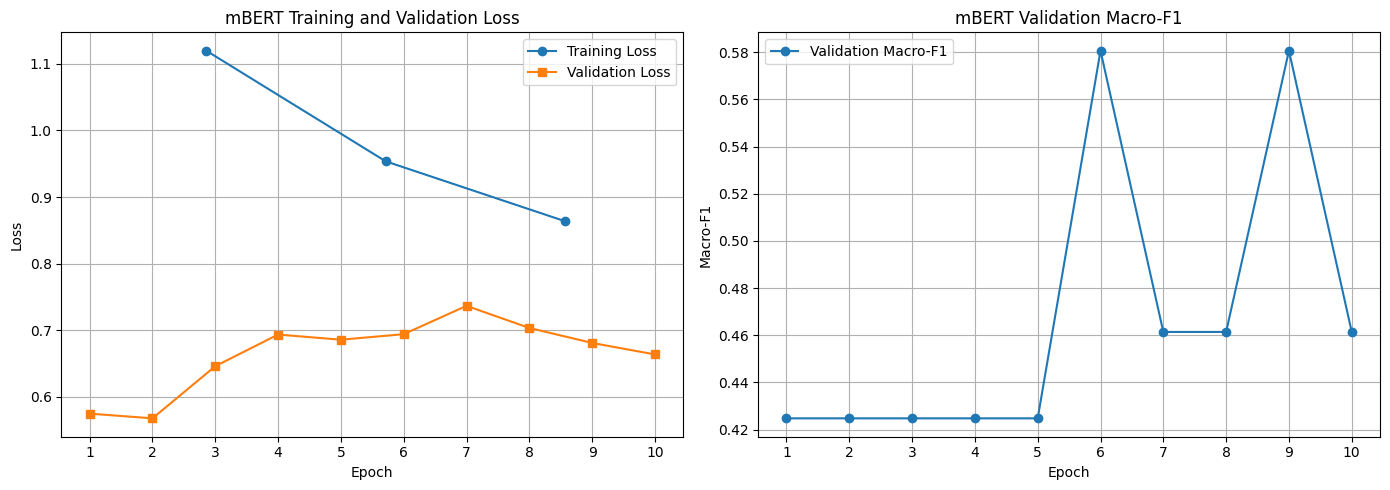

Training loss records: 3
Validation records: 10
Validation Macro-F1 records: 10


In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 7: PLOT TRAINING AND VALIDATION CURVES
# TASK: Visualize loss and Macro-F1 across 10 epochs
# ============================================================

import matplotlib.pyplot as plt

logs = trainer.state.log_history

train_epochs = [
    x["epoch"] for x in logs
    if "loss" in x and "eval_loss" not in x and "epoch" in x
]

train_losses = [
    x["loss"] for x in logs
    if "loss" in x and "eval_loss" not in x
]

val_epochs = [
    x["epoch"] for x in logs if "eval_loss" in x
]

val_losses = [
    x["eval_loss"] for x in logs if "eval_loss" in x
]

val_f1 = [
    x["eval_f1"] for x in logs if "eval_f1" in x
]

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(train_epochs, train_losses, marker="o", label="Training Loss")
plt.plot(val_epochs, val_losses, marker="s", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("mBERT Training and Validation Loss")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(val_epochs, val_f1, marker="o", label="Validation Macro-F1")
plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("mBERT Validation Macro-F1")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Training loss records:", len(train_losses))
print("Validation records:", len(val_losses))
print("Validation Macro-F1 records:", len(val_f1))

mBERT TEST PERFORMANCE
Accuracy: 0.8125
Macro Precision: 0.7497
Macro Recall: 0.6522
Macro F1: 0.6757
Weighted F1: 0.7902

CLASS-WISE CLASSIFICATION REPORT
                  precision    recall  f1-score   support

Non-Hallucinated       0.67      0.36      0.47       168
    Hallucinated       0.83      0.95      0.89       568

        accuracy                           0.81       736
       macro avg       0.75      0.65      0.68       736
    weighted avg       0.79      0.81      0.79       736



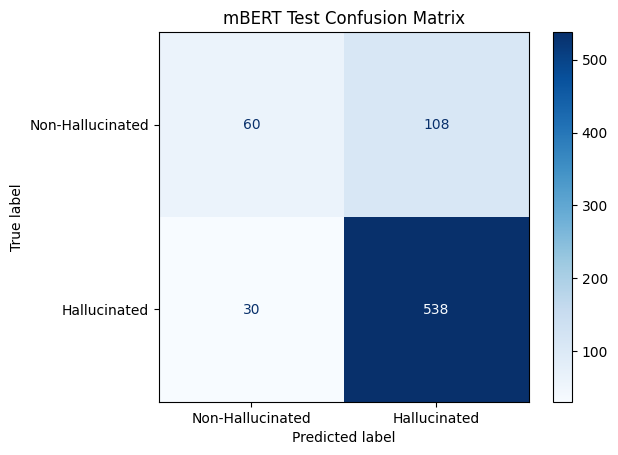

In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 8: FINAL TEST EVALUATION
# TASK: Calculate test metrics and display confusion matrix
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Predict using the best selected model
predictions = trainer.predict(test_dataset)

mbert_test_pred = np.argmax(
    predictions.predictions, axis=1
)

print("mBERT TEST PERFORMANCE")
print("=" * 55)

print("Accuracy:",
      round(accuracy_score(y_test, mbert_test_pred), 4))

print("Macro Precision:",
      round(precision_score(y_test, mbert_test_pred,
                            average="macro", zero_division=0), 4))

print("Macro Recall:",
      round(recall_score(y_test, mbert_test_pred,
                         average="macro", zero_division=0), 4))

print("Macro F1:",
      round(f1_score(y_test, mbert_test_pred,
                     average="macro", zero_division=0), 4))

print("Weighted F1:",
      round(f1_score(y_test, mbert_test_pred,
                     average="weighted", zero_division=0), 4))

print("\nCLASS-WISE CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    mbert_test_pred,
    labels=[0, 1],
    target_names=["Non-Hallucinated", "Hallucinated"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    mbert_test_pred,
    labels=[0, 1],
    display_labels=["Non-Hallucinated", "Hallucinated"],
    cmap="Blues",
    values_format="d"
)

plt.title("mBERT Test Confusion Matrix")
plt.show()

In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 9: SAVE TRAINED MODEL
# TASK: Save the best mBERT model and tokenizer
# ============================================================

import os

save_path = "/content/mbert_hallucination_model"

os.makedirs(save_path, exist_ok=True)

trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)

print("mBERT model saved successfully.")
print("Saved location:", save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

mBERT model saved successfully.
Saved location: /content/mbert_hallucination_model


In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 10: SAVE TEST PREDICTIONS AND METRICS
# TASK: Export actual labels, predicted labels and evaluation metrics
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report
)

mbert_results = pd.DataFrame({
    "Actual_Label": y_test,
    "Predicted_Label": mbert_test_pred
})

mbert_results["Actual_Class"] = mbert_results["Actual_Label"].map({
    0: "Non-Hallucinated",
    1: "Hallucinated"
})

mbert_results["Predicted_Class"] = mbert_results["Predicted_Label"].map({
    0: "Non-Hallucinated",
    1: "Hallucinated"
})

mbert_results.to_csv(
    "/content/mbert_test_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

mbert_metrics = {
    "Model": "mBERT",
    "Accuracy": accuracy_score(y_test, mbert_test_pred),
    "Macro_Precision": precision_score(
        y_test, mbert_test_pred, average="macro", zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_test, mbert_test_pred, average="macro", zero_division=0
    ),
    "Macro_F1": f1_score(
        y_test, mbert_test_pred, average="macro", zero_division=0
    ),
    "Weighted_F1": f1_score(
        y_test, mbert_test_pred, average="weighted", zero_division=0
    )
}

pd.DataFrame([mbert_metrics]).to_csv(
    "/content/mbert_test_metrics.csv",
    index=False
)

print("mBERT predictions and metrics saved successfully.")
print(pd.DataFrame([mbert_metrics]).round(4))

mBERT predictions and metrics saved successfully.
   Model  Accuracy  Macro_Precision  Macro_Recall  Macro_F1  Weighted_F1
0  mBERT    0.8125           0.7497        0.6522    0.6757       0.7902


In [ ]:
# ============================================================
# MODEL 3: mBERT
# CELL 11: DOWNLOAD MODEL RESULTS
# TASK: Download saved test predictions and evaluation metrics
# ============================================================

from google.colab import files

files.download("/content/mbert_test_predictions.csv")
files.download("/content/mbert_test_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 1: IMPORT LIBRARIES AND CONFIGURE ENVIRONMENT
# TASK: Prepare deep learning, transformer and evaluation libraries
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Hybrid model environment prepared.")
print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Hybrid model environment prepared.
PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 2: LOAD mBERT TOKENIZER
# TASK: Tokenize training, validation and testing text
# ============================================================

MODEL_NAME = "bert-base-multilingual-cased"
MAX_LENGTH = 128

hybrid_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings_hybrid = hybrid_tokenizer(
    train_text,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

val_encodings_hybrid = hybrid_tokenizer(
    val_text,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

test_encodings_hybrid = hybrid_tokenizer(
    test_text,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

print("Hybrid tokenizer prepared.")
print("Training samples:", len(train_text))
print("Validation samples:", len(val_text))
print("Testing samples:", len(test_text))
print("Maximum token length:", MAX_LENGTH)

Hybrid tokenizer prepared.
Training samples: 2794
Validation samples: 585
Testing samples: 736
Maximum token length: 128


In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 3: CREATE HYBRID DATASET
# TASK: Combine tokenized text, KB features and labels
# ============================================================

class HybridDataset(Dataset):
    def __init__(self, encodings, kb_features, labels):
        self.input_ids = torch.tensor(
            encodings["input_ids"], dtype=torch.long
        )
        self.attention_mask = torch.tensor(
            encodings["attention_mask"], dtype=torch.long
        )
        self.kb_features = torch.tensor(
            np.asarray(kb_features), dtype=torch.float32
        )
        self.labels = torch.tensor(
            np.asarray(labels), dtype=torch.long
        )

        assert len(self.input_ids) == len(self.kb_features) == len(self.labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "input_ids": self.input_ids[index],
            "attention_mask": self.attention_mask[index],
            "kb_features": self.kb_features[index],
            "labels": self.labels[index]
        }


train_dataset_hybrid = HybridDataset(
    train_encodings_hybrid, X_train_kb, y_train
)

val_dataset_hybrid = HybridDataset(
    val_encodings_hybrid, X_val_kb, y_val
)

test_dataset_hybrid = HybridDataset(
    test_encodings_hybrid, X_test_kb, y_test
)

print("Hybrid datasets created successfully.")
print("Training:", len(train_dataset_hybrid))
print("Validation:", len(val_dataset_hybrid))
print("Testing:", len(test_dataset_hybrid))
print("KB feature count:", train_dataset_hybrid.kb_features.shape[1])

Hybrid datasets created successfully.
Training: 2794
Validation: 585
Testing: 736
KB feature count: 4


In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 4: CREATE DATALOADERS
# TASK: Prepare batched data for model training and evaluation
# ============================================================

BATCH_SIZE = 8

train_loader_hybrid = DataLoader(
    train_dataset_hybrid,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_hybrid = DataLoader(
    val_dataset_hybrid,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_hybrid = DataLoader(
    test_dataset_hybrid,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Hybrid DataLoaders created.")
print("Training batches:", len(train_loader_hybrid))
print("Validation batches:", len(val_loader_hybrid))
print("Testing batches:", len(test_loader_hybrid))
print("Batch size:", BATCH_SIZE)

Hybrid DataLoaders created.
Training batches: 350
Validation batches: 74
Testing batches: 92
Batch size: 8


In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 5: DEFINE HYBRID MODEL
# TASK: Combine contextual text representation with KB features
# ============================================================

from torch.nn.utils.rnn import pack_padded_sequence

class HybridKBClassifier(nn.Module):
    def __init__(self, model_name, kb_feature_count=4):
        super().__init__()

        self.bert = AutoModel.from_pretrained(model_name)

        self.lstm = nn.LSTM(
            input_size=self.bert.config.hidden_size,
            hidden_size=128,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)

        self.classifier = nn.Linear(
            256 + kb_feature_count,
            2
        )

    def forward(self, input_ids, attention_mask, kb_features):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        sequence_output = outputs.last_hidden_state

        lengths = attention_mask.sum(dim=1).cpu()

        packed_sequence = pack_padded_sequence(
            sequence_output,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed_sequence)

        text_features = torch.cat(
            (hidden[-2], hidden[-1]),
            dim=1
        )

        combined_features = torch.cat(
            (text_features, kb_features),
            dim=1
        )

        logits = self.classifier(
            self.dropout(combined_features)
        )

        return logits


hybrid_model = HybridKBClassifier(
    model_name=MODEL_NAME,
    kb_feature_count=train_dataset_hybrid.kb_features.shape[1]
).to(device)

print("Hybrid mBERT-BiLSTM-KB model created.")
print("Text representation: 256 dimensions")
print("KB features:", train_dataset_hybrid.kb_features.shape[1])
print("Classifier input:", hybrid_model.classifier.in_features)
print("Device:", device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Hybrid mBERT-BiLSTM-KB model created.
Text representation: 256 dimensions
KB features: 4
Classifier input: 260
Device: cuda


In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 6: DEFINE LOSS FUNCTION AND OPTIMIZER
# TASK: Handle class imbalance and configure model optimization
# ============================================================

from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=np.asarray(y_train)
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

optimizer = optim.AdamW(
    [
        {
            "params": hybrid_model.bert.parameters(),
            "lr": 2e-5
        },
        {
            "params": list(hybrid_model.lstm.parameters()) +
                      list(hybrid_model.classifier.parameters()),
            "lr": 1e-3
        }
    ],
    weight_decay=0.01
)

print("Loss function and optimizer configured.")
print("Class weights:", class_weights)
print("mBERT learning rate: 2e-5")
print("BiLSTM and classifier learning rate: 1e-3")
print("Weight decay: 0.01")

Loss function and optimizer configured.
Class weights: [1.95111732 0.67228104]
mBERT learning rate: 2e-5
BiLSTM and classifier learning rate: 1e-3
Weight decay: 0.01


In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 7: TRAIN HYBRID MODEL
# TASK: Train for 10 epochs and select the best validation model
# ============================================================

from copy import deepcopy
from sklearn.metrics import f1_score, accuracy_score

EPOCHS = 10

history_hybrid = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

best_val_f1 = -1.0
best_hybrid_state = None

for epoch in range(EPOCHS):

    hybrid_model.train()
    train_loss_total = 0
    train_true, train_pred = [], []

    for batch in train_loader_hybrid:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        kb_features = batch["kb_features"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        logits = hybrid_model(
            input_ids,
            attention_mask,
            kb_features
        )

        loss = criterion(logits, labels)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            hybrid_model.parameters(), max_norm=1.0
        )

        optimizer.step()

        train_loss_total += loss.item()
        train_pred.extend(torch.argmax(logits, dim=1).cpu().numpy())
        train_true.extend(labels.cpu().numpy())

    train_loss = train_loss_total / len(train_loader_hybrid)
    train_accuracy = accuracy_score(train_true, train_pred)

    hybrid_model.eval()
    val_loss_total = 0
    val_true, val_pred = [], []

    with torch.no_grad():
        for batch in val_loader_hybrid:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            kb_features = batch["kb_features"].to(device)
            labels = batch["labels"].to(device)

            logits = hybrid_model(
                input_ids,
                attention_mask,
                kb_features
            )

            loss = criterion(logits, labels)
            val_loss_total += loss.item()

            val_pred.extend(
                torch.argmax(logits, dim=1).cpu().numpy()
            )
            val_true.extend(labels.cpu().numpy())

    val_loss = val_loss_total / len(val_loader_hybrid)
    val_accuracy = accuracy_score(val_true, val_pred)
    val_macro_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    history_hybrid["train_loss"].append(train_loss)
    history_hybrid["val_loss"].append(val_loss)
    history_hybrid["train_accuracy"].append(train_accuracy)
    history_hybrid["val_accuracy"].append(val_accuracy)
    history_hybrid["val_macro_f1"].append(val_macro_f1)

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_hybrid_state = deepcopy(hybrid_model.state_dict())

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro-F1: {val_macro_f1:.4f}"
    )

if best_hybrid_state is None:
    raise RuntimeError("No valid hybrid model checkpoint was saved.")

hybrid_model.load_state_dict(best_hybrid_state)

print("\nTraining completed.")
print("Best validation Macro-F1:", round(best_val_f1, 4))

Epoch 1/10 | Train Loss: 0.7120 | Val Loss: 0.6921 | Train Acc: 0.5408 | Val Acc: 0.7385 | Val Macro-F1: 0.4248
Epoch 2/10 | Train Loss: 0.6936 | Val Loss: 0.6958 | Train Acc: 0.6027 | Val Acc: 0.4154 | Val Macro-F1: 0.4098
Epoch 3/10 | Train Loss: 0.6914 | Val Loss: 0.6927 | Train Acc: 0.5938 | Val Acc: 0.7111 | Val Macro-F1: 0.4156
Epoch 4/10 | Train Loss: 0.6900 | Val Loss: 0.6934 | Train Acc: 0.6203 | Val Acc: 0.4684 | Val Macro-F1: 0.4450
Epoch 5/10 | Train Loss: 0.6874 | Val Loss: 0.6929 | Train Acc: 0.6206 | Val Acc: 0.6838 | Val Macro-F1: 0.4729
Epoch 6/10 | Train Loss: 0.6925 | Val Loss: 0.7000 | Train Acc: 0.6288 | Val Acc: 0.4410 | Val Macro-F1: 0.4408
Epoch 7/10 | Train Loss: 0.6883 | Val Loss: 0.6962 | Train Acc: 0.5866 | Val Acc: 0.4410 | Val Macro-F1: 0.4324
Epoch 8/10 | Train Loss: 0.6884 | Val Loss: 0.6949 | Train Acc: 0.6220 | Val Acc: 0.4940 | Val Macro-F1: 0.4656
Epoch 9/10 | Train Loss: 0.6892 | Val Loss: 0.6939 | Train Acc: 0.6170 | Val Acc: 0.4940 | Val Macro-F1:

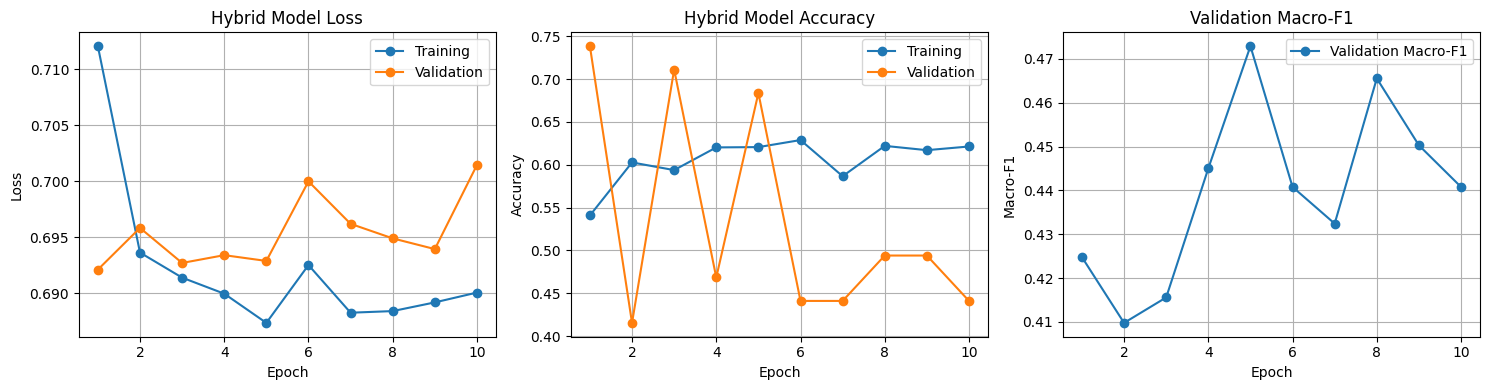

In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 8: PLOT TRAINING CURVES
# TASK: Visualize loss, accuracy and validation macro-F1
# ============================================================

epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(epochs, history_hybrid["train_loss"], marker="o", label="Training")
plt.plot(epochs, history_hybrid["val_loss"], marker="o", label="Validation")
plt.title("Hybrid Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(epochs, history_hybrid["train_accuracy"], marker="o", label="Training")
plt.plot(epochs, history_hybrid["val_accuracy"], marker="o", label="Validation")
plt.title("Hybrid Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(epochs, history_hybrid["val_macro_f1"], marker="o", label="Validation Macro-F1")
plt.title("Validation Macro-F1")
plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

HYBRID MODEL TEST PERFORMANCE
Accuracy:          0.7310
Macro Precision:   0.5118
Macro Recall:      0.5050
Macro F1-score:    0.4862
Weighted F1-score: 0.6789

CLASSIFICATION REPORT
                  precision    recall  f1-score   support

Non-Hallucinated       0.25      0.09      0.13       168
    Hallucinated       0.77      0.92      0.84       568

        accuracy                           0.73       736
       macro avg       0.51      0.51      0.49       736
    weighted avg       0.65      0.73      0.68       736



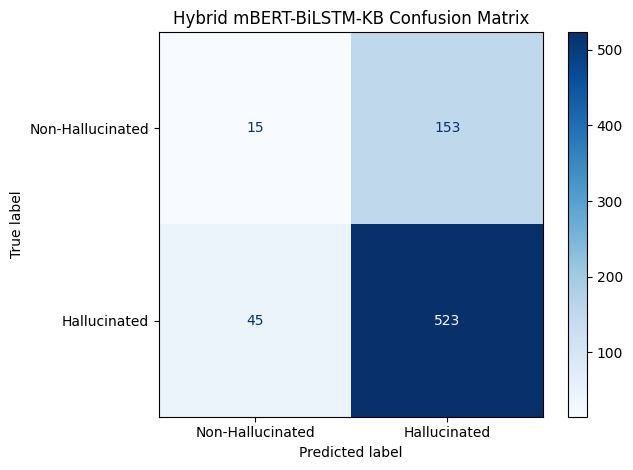

In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 9: TEST SET EVALUATION
# TASK: Calculate final metrics and display classification report
# ============================================================

hybrid_model.eval()

hybrid_test_true = []
hybrid_test_pred = []

with torch.no_grad():
    for batch in test_loader_hybrid:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        kb_features = batch["kb_features"].to(device)
        labels = batch["labels"].to(device)

        logits = hybrid_model(
            input_ids,
            attention_mask,
            kb_features
        )

        predictions = torch.argmax(logits, dim=1)

        hybrid_test_pred.extend(predictions.cpu().numpy())
        hybrid_test_true.extend(labels.cpu().numpy())

hybrid_test_accuracy = accuracy_score(
    hybrid_test_true, hybrid_test_pred
)

hybrid_test_precision = precision_score(
    hybrid_test_true, hybrid_test_pred,
    average="macro", zero_division=0
)

hybrid_test_recall = recall_score(
    hybrid_test_true, hybrid_test_pred,
    average="macro", zero_division=0
)

hybrid_test_f1 = f1_score(
    hybrid_test_true, hybrid_test_pred,
    average="macro", zero_division=0
)

hybrid_test_weighted_f1 = f1_score(
    hybrid_test_true, hybrid_test_pred,
    average="weighted", zero_division=0
)

print("HYBRID MODEL TEST PERFORMANCE")
print("=" * 55)
print(f"Accuracy:          {hybrid_test_accuracy:.4f}")
print(f"Macro Precision:   {hybrid_test_precision:.4f}")
print(f"Macro Recall:      {hybrid_test_recall:.4f}")
print(f"Macro F1-score:    {hybrid_test_f1:.4f}")
print(f"Weighted F1-score: {hybrid_test_weighted_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    hybrid_test_true,
    hybrid_test_pred,
    labels=[0, 1],
    target_names=["Non-Hallucinated", "Hallucinated"],
    zero_division=0
))

cm = confusion_matrix(
    hybrid_test_true,
    hybrid_test_pred,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Hallucinated", "Hallucinated"]
).plot(cmap="Blues", values_format="d")

plt.title("Hybrid mBERT-BiLSTM-KB Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 10: SAVE TRAINED MODEL
# TASK: Save model weights, tokenizer and architecture configuration
# ============================================================

import json

HYBRID_SAVE_DIR = "/content/hybrid_mbert_bilstm_kb"

os.makedirs(HYBRID_SAVE_DIR, exist_ok=True)

# Save trained model weights
torch.save(
    hybrid_model.state_dict(),
    os.path.join(HYBRID_SAVE_DIR, "hybrid_model_weights.pth")
)

# Save tokenizer
hybrid_tokenizer.save_pretrained(HYBRID_SAVE_DIR)

# Save model configuration
hybrid_config = {
    "model_name": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "lstm_hidden_size": 128,
    "bidirectional": True,
    "dropout": 0.3,
    "kb_feature_count": int(train_dataset_hybrid.kb_features.shape[1]),
    "number_of_classes": 2,
    "best_validation_macro_f1": float(best_val_f1)
}

with open(
    os.path.join(HYBRID_SAVE_DIR, "hybrid_config.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(hybrid_config, file, indent=4)

print("Hybrid model saved successfully.")
print("Save directory:", HYBRID_SAVE_DIR)
print("Saved files:", os.listdir(HYBRID_SAVE_DIR))

Hybrid model saved successfully.
Save directory: /content/hybrid_mbert_bilstm_kb
Saved files: ['tokenizer.json', 'hybrid_config.json', 'tokenizer_config.json', 'hybrid_model_weights.pth']


In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 11: SAVE TEST RESULTS
# TASK: Export predictions and performance metrics to CSV files
# ============================================================

hybrid_predictions_df = pd.DataFrame({
    "Actual_Label": hybrid_test_true,
    "Predicted_Label": hybrid_test_pred,
    "Actual_Class": [
        "Hallucinated" if x == 1 else "Non-Hallucinated"
        for x in hybrid_test_true
    ],
    "Predicted_Class": [
        "Hallucinated" if x == 1 else "Non-Hallucinated"
        for x in hybrid_test_pred
    ]
})

hybrid_metrics_df = pd.DataFrame([{
    "Model": "Hybrid mBERT-BiLSTM-KB",
    "Accuracy": hybrid_test_accuracy,
    "Macro_Precision": hybrid_test_precision,
    "Macro_Recall": hybrid_test_recall,
    "Macro_F1": hybrid_test_f1,
    "Weighted_F1": hybrid_test_weighted_f1
}])

predictions_path = "/content/hybrid_test_predictions.csv"
metrics_path = "/content/hybrid_test_metrics.csv"

hybrid_predictions_df.to_csv(
    predictions_path, index=False, encoding="utf-8-sig"
)

hybrid_metrics_df.to_csv(
    metrics_path, index=False, encoding="utf-8-sig"
)

print("Test results saved successfully.")
print(predictions_path)
print(metrics_path)

display(hybrid_metrics_df)

Test results saved successfully.
/content/hybrid_test_predictions.csv
/content/hybrid_test_metrics.csv


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
0,Hybrid mBERT-BiLSTM-KB,0.730978,0.511834,0.50503,0.486207,0.67894


In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 12: DOWNLOAD RESULTS
# TASK: Download prediction and evaluation CSV files
# ============================================================

from google.colab import files

files.download("/content/hybrid_test_predictions.csv")
files.download("/content/hybrid_test_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# MODEL 4: HYBRID mBERT-BiLSTM + KNOWLEDGE BASE
# CELL 13: VERIFY SAVED FILES
# TASK: Confirm all model and research output files exist
# ============================================================

required_files = [
    "/content/hybrid_mbert_bilstm_kb/hybrid_model_weights.pth",
    "/content/hybrid_mbert_bilstm_kb/hybrid_config.json",
    "/content/hybrid_mbert_bilstm_kb/tokenizer_config.json",
    "/content/hybrid_test_predictions.csv",
    "/content/hybrid_test_metrics.csv"
]

print("HYBRID MODEL FILE VERIFICATION")
print("=" * 50)

for path in required_files:
    print(
        "[OK]" if os.path.exists(path) else "[MISSING]",
        os.path.basename(path)
    )

print("\nPrediction rows:", len(hybrid_predictions_df))
print("Metric rows:", len(hybrid_metrics_df))
print("Best validation Macro-F1:", round(best_val_f1, 4))
print("Final test Macro-F1:", round(hybrid_test_f1, 4))

HYBRID MODEL FILE VERIFICATION
[OK] hybrid_model_weights.pth
[OK] hybrid_config.json
[OK] tokenizer_config.json
[OK] hybrid_test_predictions.csv
[OK] hybrid_test_metrics.csv

Prediction rows: 736
Metric rows: 1
Best validation Macro-F1: 0.4729
Final test Macro-F1: 0.4862


In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# CELL 1: RECALCULATE FOUR-MODEL TEST PERFORMANCE
# TASK: Calculate metrics directly from test predictions
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

model_predictions = {
    "TF-IDF + SVM": svm_test_pred,
    "BiLSTM": bilstm_test_pred,
    "mBERT": mbert_test_pred,
    "Hybrid mBERT-BiLSTM-KB": hybrid_test_pred
}

actual_labels = np.asarray(y_test)

comparison_results = []

for model_name, predictions in model_predictions.items():

    predictions = np.asarray(predictions)

    if len(predictions) != len(actual_labels):
        raise ValueError(
            f"{model_name}: prediction count does not match test labels."
        )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(actual_labels, predictions),
        "Macro_Precision": precision_score(
            actual_labels, predictions, average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(
            actual_labels, predictions, average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            actual_labels, predictions, average="macro", zero_division=0
        ),
        "Weighted_F1": f1_score(
            actual_labels, predictions, average="weighted", zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

comparison_df.to_csv(
    "/content/four_model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Test samples:", len(actual_labels))
print("Comparison saved successfully.")

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
0,TF-IDF + SVM,0.8573,0.8015,0.7818,0.7908,0.8549
1,BiLSTM,0.8967,0.8478,0.8702,0.8581,0.8983
2,mBERT,0.8125,0.7497,0.6522,0.6757,0.7902
3,Hybrid mBERT-BiLSTM-KB,0.7310,0.5118,0.5050,0.4862,0.6789


Test samples: 736
Comparison saved successfully.


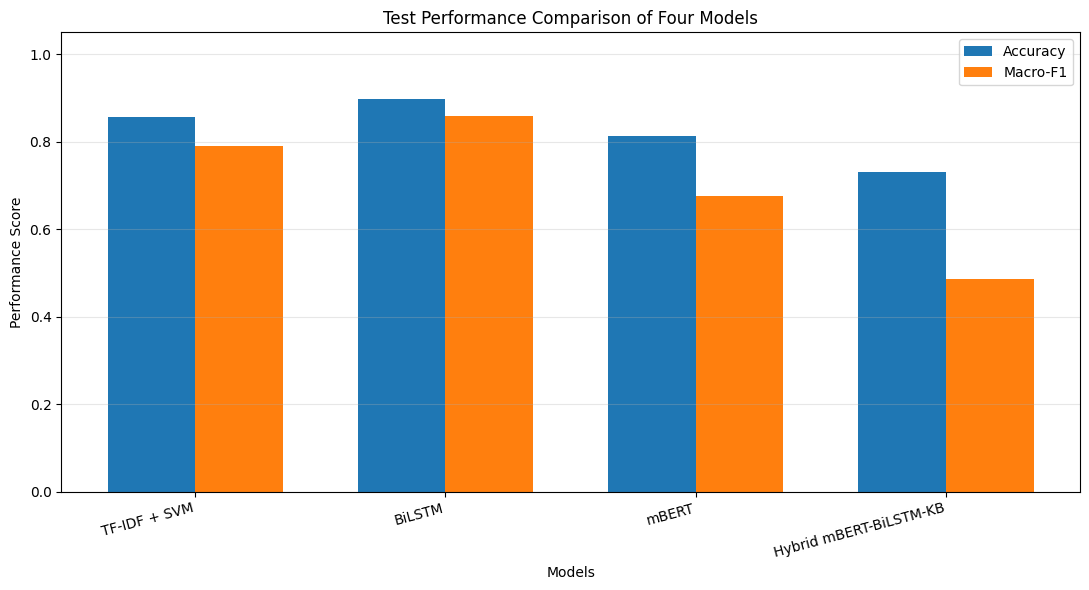

Performance comparison graph saved.


In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# CELL 2: PERFORMANCE COMPARISON GRAPH
# TASK: Visualize accuracy and macro-F1 across four models
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(comparison_df))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width/2,
    comparison_df["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width/2,
    comparison_df["Macro_F1"],
    width,
    label="Macro-F1"
)

plt.xticks(
    x,
    comparison_df["Model"],
    rotation=15,
    ha="right"
)

plt.ylabel("Performance Score")
plt.xlabel("Models")
plt.title("Test Performance Comparison of Four Models")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/content/four_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Performance comparison graph saved.")

TEST SET CLASS DISTRIBUTION
0    168
1    568
Name: count, dtype: int64

TF-IDF + SVM
                  precision    recall  f1-score   support

Non-Hallucinated       0.71      0.64      0.67       168
    Hallucinated       0.90      0.92      0.91       568

        accuracy                           0.86       736
       macro avg       0.80      0.78      0.79       736
    weighted avg       0.85      0.86      0.85       736


BiLSTM
                  precision    recall  f1-score   support

Non-Hallucinated       0.75      0.82      0.78       168
    Hallucinated       0.95      0.92      0.93       568

        accuracy                           0.90       736
       macro avg       0.85      0.87      0.86       736
    weighted avg       0.90      0.90      0.90       736


mBERT
                  precision    recall  f1-score   support

Non-Hallucinated       0.67      0.36      0.47       168
    Hallucinated       0.83      0.95      0.89       568

        accuracy     

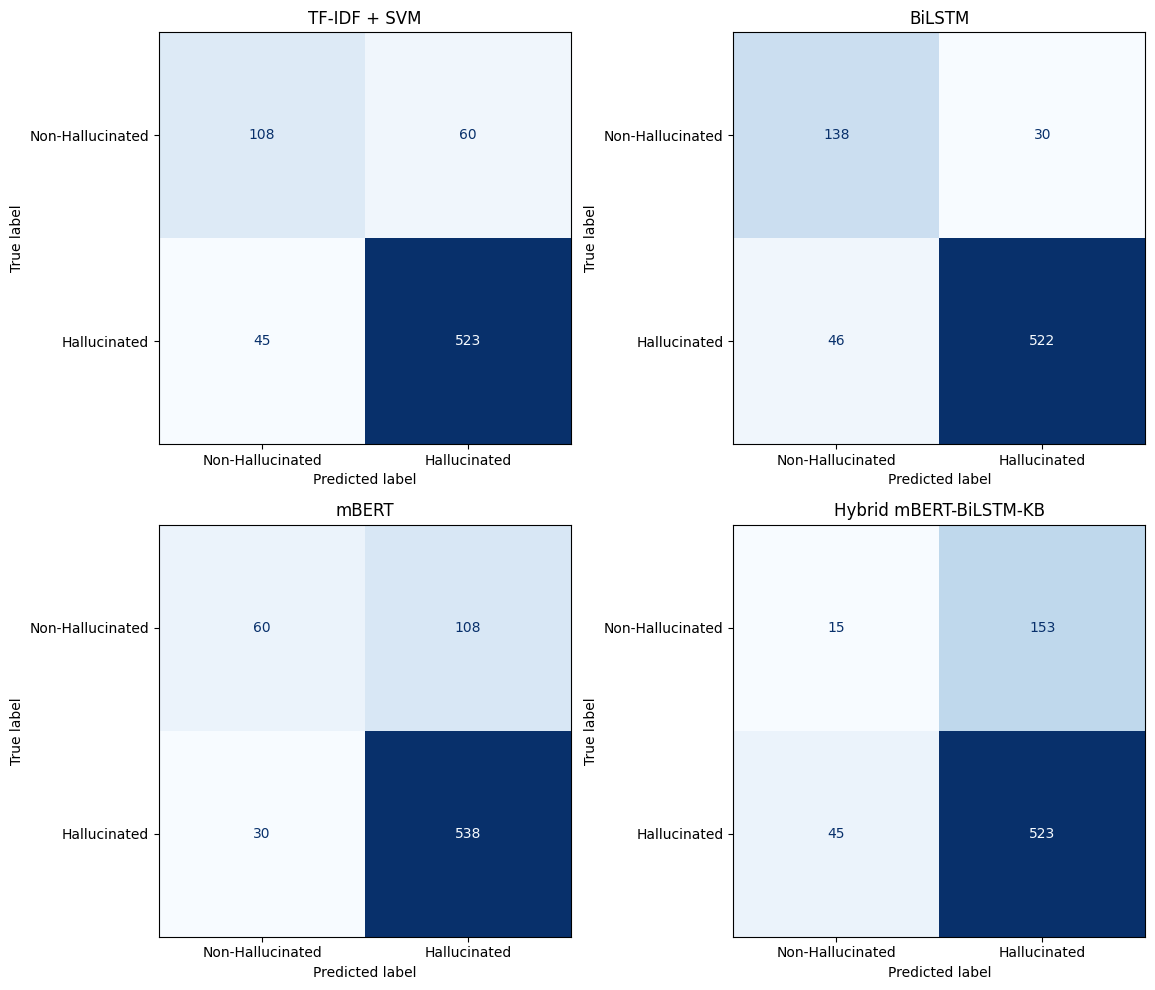

In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# CELL 3: CLASS-WISE DIAGNOSTIC ANALYSIS
# TASK: Examine prediction errors and class imbalance
# ============================================================

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

models = {
    "TF-IDF + SVM": svm_test_pred,
    "BiLSTM": bilstm_test_pred,
    "mBERT": mbert_test_pred,
    "Hybrid mBERT-BiLSTM-KB": hybrid_test_pred
}

print("TEST SET CLASS DISTRIBUTION")
print(pd.Series(y_test).value_counts().sort_index())

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for (name, predictions), ax in zip(models.items(), axes.flatten()):

    print("\n", "=" * 55)
    print(name)
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Non-Hallucinated", "Hallucinated"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    from sklearn.metrics import ConfusionMatrixDisplay
    ConfusionMatrixDisplay(
        cm,
        display_labels=["Non-Hallucinated", "Hallucinated"]
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.savefig("/content/four_model_confusion_matrices.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# CELL 4: HYBRID MODEL DIAGNOSTICS
# TASK: Inspect prediction distribution and KB feature quality
# ============================================================

import numpy as np
import pandas as pd

# 1. Actual and predicted class distributions
print("ACTUAL TEST CLASS DISTRIBUTION")
print(pd.Series(y_test).value_counts().sort_index())

print("\nHYBRID PREDICTED CLASS DISTRIBUTION")
print(pd.Series(hybrid_test_pred).value_counts().sort_index())

# 2. Prediction distribution by model
print("\nPREDICTION DISTRIBUTION BY MODEL")

for name, predictions in models.items():
    print(f"\n{name}")
    print(pd.Series(predictions).value_counts().sort_index())

# 3. Knowledge-base feature statistics
feature_names = [
    "Question_Max_Similarity",
    "Question_Mean_Similarity",
    "Answer_Max_Similarity",
    "Answer_Object_Similarity"
]

kb_train_df = pd.DataFrame(
    X_train_kb,
    columns=feature_names
)

kb_train_df["Label"] = np.asarray(y_train)

print("\nKB FEATURE STATISTICS BY TRAINING CLASS")
display(kb_train_df.groupby("Label")[feature_names].agg(
    ["mean", "std", "min", "max"]
).round(4))

# 4. Check missing and infinite feature values
print("\nKB FEATURE QUALITY CHECK")
print("NaN values:", np.isnan(X_train_kb).sum())
print("Infinite values:", np.isinf(X_train_kb).sum())
print("Feature shape:", X_train_kb.shape)

print("\nHybrid diagnostic inspection completed.")

ACTUAL TEST CLASS DISTRIBUTION
0    168
1    568
Name: count, dtype: int64

HYBRID PREDICTED CLASS DISTRIBUTION
0     60
1    676
Name: count, dtype: int64

PREDICTION DISTRIBUTION BY MODEL

TF-IDF + SVM
0    153
1    583
Name: count, dtype: int64

BiLSTM
0    184
1    552
Name: count, dtype: int64

mBERT
0     90
1    646
Name: count, dtype: int64

Hybrid mBERT-BiLSTM-KB
0     60
1    676
Name: count, dtype: int64

KB FEATURE STATISTICS BY TRAINING CLASS


Question_Max_Similarity                          \
                         mean     std     min     max   
Label                                                   
0                      0.3334  0.1428  0.0928  0.7523   
1                      0.3397  0.1476  0.0928  0.7523   

      Question_Mean_Similarity                         Answer_Max_Similarity  \
                          mean     std     min     max                  mean   
Label                                                                          
0                       0.2825  0.0996  0.0859  0.5263                0.3102   
1                       0.2867  0.1031  0.0859  0.5263                0.3013   

                              Answer_Object_Similarity                       
          std     min     max                     mean     std  min     max  
Label                                                                        
0      0.1417  0.0962  0.7203                   0.2290  0.1511  0.0  0.5246  
1      0.1437  0.0397  0.7426                   0.1758  0.1835  0.0  0.5231


KB FEATURE QUALITY CHECK
NaN values: 0
Infinite values: 0
Feature shape: (2794, 4)

Hybrid diagnostic inspection completed.


,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1
Epoch,,,,,
1,0.7120,0.6921,0.5408,0.7385,0.4248
2,0.6936,0.6958,0.6027,0.4154,0.4098
3,0.6914,0.6927,0.5938,0.7111,0.4156
4,0.6900,0.6934,0.6203,0.4684,0.4450
5,0.6874,0.6929,0.6206,0.6838,0.4729
6,0.6925,0.7000,0.6288,0.4410,0.4408
7,0.6883,0.6962,0.5866,0.4410,0.4324
8,0.6884,0.6949,0.6220,0.4940,0.4656
9,0.6892,0.6939,0.6170,0.4940,0.4503


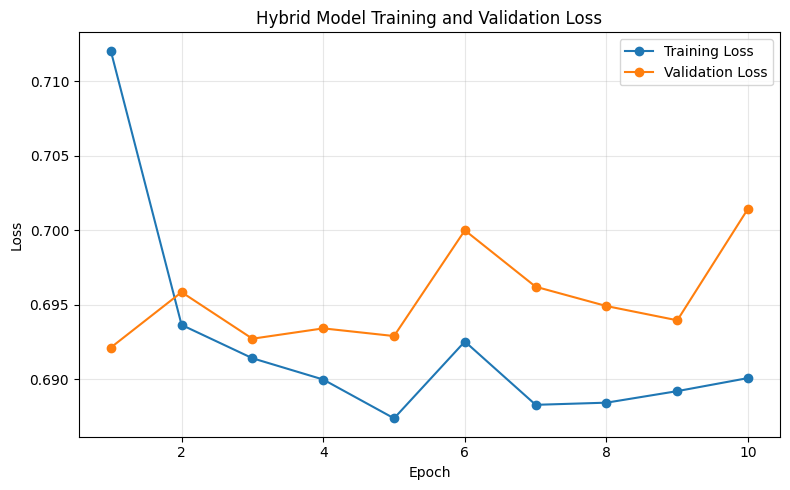

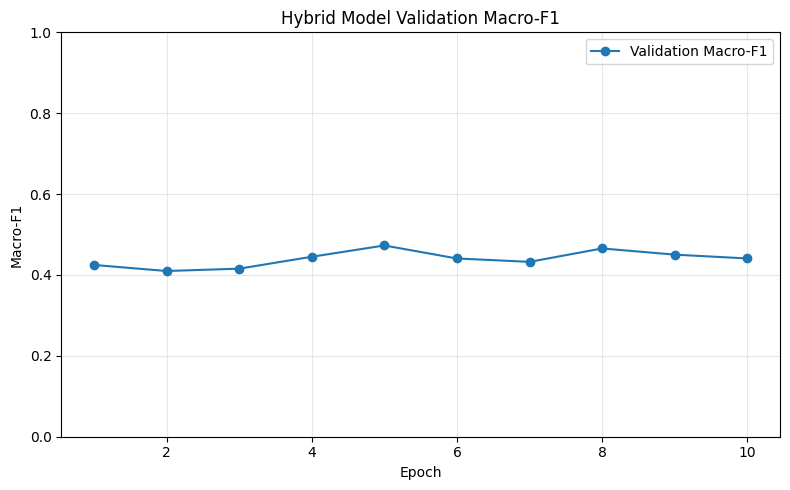

Best validation Macro-F1: 0.4729
Final test Macro-F1: 0.4862


In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# CELL 5: TRAINING BEHAVIOR ANALYSIS
# TASK: Examine convergence and overfitting across epochs
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

hybrid_history_df = pd.DataFrame(history_hybrid)

hybrid_history_df.index = range(1, len(hybrid_history_df) + 1)
hybrid_history_df.index.name = "Epoch"

display(hybrid_history_df.round(4))

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(
    hybrid_history_df.index,
    hybrid_history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    hybrid_history_df.index,
    hybrid_history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Hybrid Model Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot validation macro-F1
plt.figure(figsize=(8, 5))

plt.plot(
    hybrid_history_df.index,
    hybrid_history_df["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("Hybrid Model Validation Macro-F1")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Best validation Macro-F1:", round(best_val_f1, 4))
print("Final test Macro-F1:", round(hybrid_test_f1, 4))

KNOWLEDGE-BASE FEATURE MEANS BY CLASS


,Question_Max_Similarity,Question_Mean_Similarity,Answer_Max_Similarity,Answer_Object_Similarity
Class,,,,
Hallucinated,0.3397,0.2867,0.3013,0.1758
Non-Hallucinated,0.3334,0.2825,0.3102,0.2290


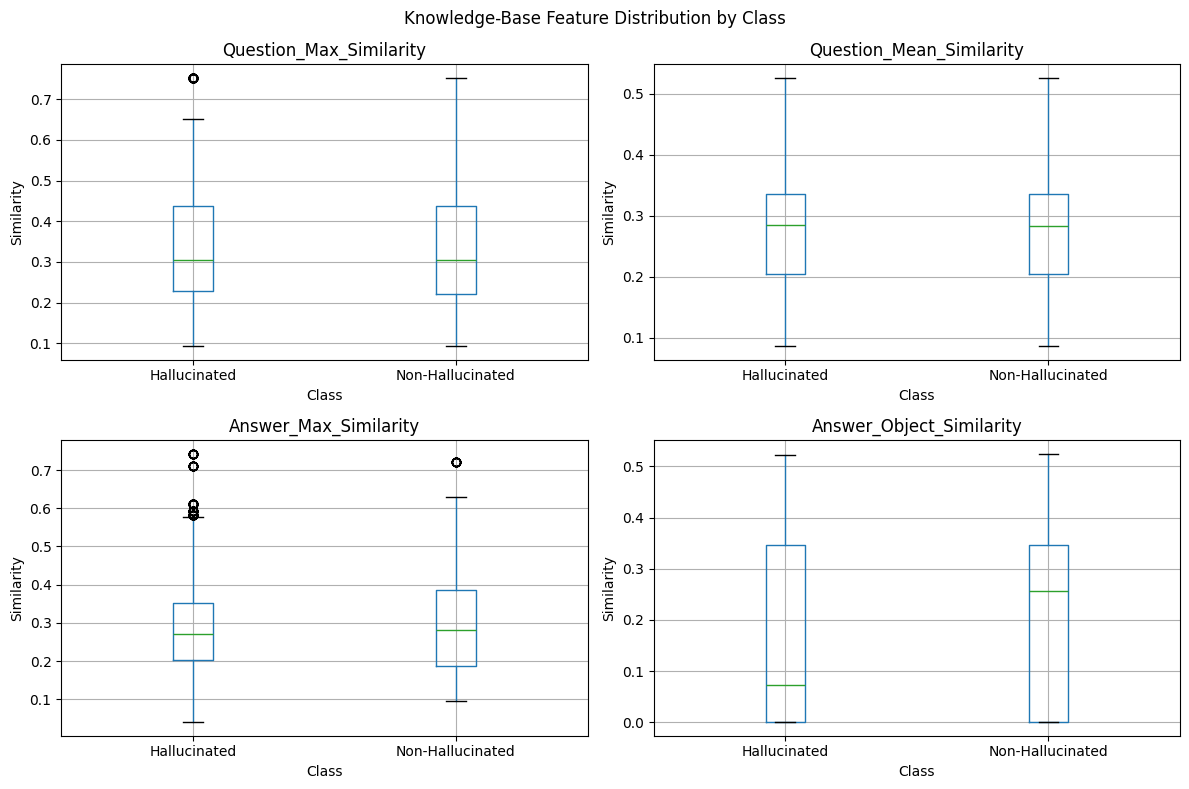

In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# CELL 6: KNOWLEDGE-BASE FEATURE ANALYSIS
# TASK: Compare KB similarity features across both classes
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

feature_names = [
    "Question_Max_Similarity",
    "Question_Mean_Similarity",
    "Answer_Max_Similarity",
    "Answer_Object_Similarity"
]

kb_analysis_df = pd.DataFrame(
    X_train_kb,
    columns=feature_names
)

kb_analysis_df["Class"] = np.where(
    np.asarray(y_train) == 1,
    "Hallucinated",
    "Non-Hallucinated"
)

# Calculate class-wise descriptive statistics
print("KNOWLEDGE-BASE FEATURE MEANS BY CLASS")

display(
    kb_analysis_df.groupby("Class")[feature_names]
    .mean()
    .round(4)
)

# Visualize feature distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(feature_names, axes.flatten()):
    kb_analysis_df.boxplot(
        column=feature,
        by="Class",
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Class")
    ax.set_ylabel("Similarity")

plt.suptitle("Knowledge-Base Feature Distribution by Class")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# CELL 7: EXPORT COMPLETE EXPERIMENT RESULTS
# TASK: Save four-model metrics and hybrid training history
# ============================================================

import os
import pandas as pd

RESULTS_DIR = "/content/amharic_hallucination_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Save model comparison
comparison_df.to_csv(
    f"{RESULTS_DIR}/four_model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save hybrid training history
hybrid_history_df.to_csv(
    f"{RESULTS_DIR}/hybrid_training_history.csv",
    encoding="utf-8-sig"
)

# Save class-wise reports for all models
with open(
    f"{RESULTS_DIR}/four_model_classification_reports.txt",
    "w",
    encoding="utf-8"
) as file:

    for model_name, predictions in models.items():
        file.write("\n" + "=" * 65 + "\n")
        file.write(model_name + "\n")
        file.write("=" * 65 + "\n")

        file.write(
            classification_report(
                y_test,
                predictions,
                labels=[0, 1],
                target_names=[
                    "Non-Hallucinated",
                    "Hallucinated"
                ],
                zero_division=0
            )
        )

print("Research results exported:")
for filename in os.listdir(RESULTS_DIR):
    print(filename)

Research results exported:
four_model_classification_reports.txt
hybrid_training_history.csv
four_model_comparison.csv


In [ ]:
# ============================================================
# ANNOTATION: AMHARIC HALLUCINATION DETECTION
# CELL 1: UPLOAD BOTH ANNOTATION FILES
# TASK: Upload Annotator 1 and Annotator 2 JSON files
# ============================================================

from google.colab import files
import os

uploaded = files.upload()

print("\nUPLOADED FILES")
print("=" * 40)

for filename in uploaded.keys():
    print(filename, "|", os.path.getsize(filename), "bytes")

Saving annotation1.json to annotation1.json
Saving annotation2.json to annotation2.json

UPLOADED FILES
annotation1.json | 801441 bytes
annotation2.json | 801441 bytes


In [ ]:
# ============================================================
# ANNOTATION: AMHARIC HALLUCINATION DETECTION
# CELL 2: LOAD AND INSPECT BOTH JSON FILES
# ============================================================

import json
import os

file1 = "/content/annotation1.json"
file2 = "/content/annotation2.json"

with open(file1, "r", encoding="utf-8") as f:
    annotation1_json = json.load(f)

with open(file2, "r", encoding="utf-8") as f:
    annotation2_json = json.load(f)

print("ANNOTATOR 1")
print("Records:", len(annotation1_json))
print("Data type:", type(annotation1_json))

print("\nFIRST RECORD - ANNOTATOR 1")
print(json.dumps(
    annotation1_json[0],
    ensure_ascii=False,
    indent=2
))

print("\nANNOTATOR 2")
print("Records:", len(annotation2_json))
print("Data type:", type(annotation2_json))

print("\nFIRST RECORD - ANNOTATOR 2")
print(json.dumps(
    annotation2_json[0],
    ensure_ascii=False,
    indent=2
))

ANNOTATOR 1
Records: 4115
Data type: <class 'list'>

FIRST RECORD - ANNOTATOR 1
{
  "id": 1,
  "question": "ኢትዮጵያ በየትኛው አህጉር ላይ ትገኛለች?",
  "answer": "ኢትዮጵያ በአውስትራሊያ ትገኛለች።",
  "label": 1
}

ANNOTATOR 2
Records: 4115
Data type: <class 'list'>

FIRST RECORD - ANNOTATOR 2
{
  "id": 1,
  "question": "ኢትዮጵያ በየትኛው አህጉር ላይ ትገኛለች?",
  "answer": "ኢትዮጵያ በአውስትራሊያ ትገኛለች።",
  "label": 1
}


In [ ]:
# ============================================================
# ANNOTATION: AMHARIC HALLUCINATION DETECTION
# CELL 3: MATCH JSON ANNOTATIONS AND CALCULATE AGREEMENT
# ============================================================

import pandas as pd
from sklearn.metrics import cohen_kappa_score, accuracy_score

# Convert JSON records to DataFrames
json_ann1 = pd.DataFrame(annotation1_json)
json_ann2 = pd.DataFrame(annotation2_json)

# Check unique IDs
assert json_ann1["id"].is_unique, "Duplicate IDs in annotation1.json"
assert json_ann2["id"].is_unique, "Duplicate IDs in annotation2.json"

# Rename annotation labels
json_ann1 = json_ann1.rename(columns={"label": "label_annotator1"})
json_ann2 = json_ann2.rename(columns={"label": "label_annotator2"})

# Match records by ID
json_merged = json_ann1.merge(
    json_ann2,
    on="id",
    how="outer",
    suffixes=("_ann1", "_ann2"),
    indicator=True
)

print("ANNOTATION RECORD MATCHING")
print("Annotator 1 records:", len(json_ann1))
print("Annotator 2 records:", len(json_ann2))
print("Matched records:", (json_merged["_merge"] == "both").sum())
print("Unmatched records:", (json_merged["_merge"] != "both").sum())

# Verify question and answer consistency
matched = json_merged[json_merged["_merge"] == "both"].copy()

content_match = (
    (matched["question_ann1"] == matched["question_ann2"]) &
    (matched["answer_ann1"] == matched["answer_ann2"])
)

print("Identical questions and answers:", content_match.sum())
print("Content mismatches:", (~content_match).sum())

# Calculate agreement only when all records match
if len(matched) == 4115 and content_match.all():

    y1 = matched["label_annotator1"]
    y2 = matched["label_annotator2"]

    assert y1.isin([0, 1]).all(), "Invalid labels in Annotator 1"
    assert y2.isin([0, 1]).all(), "Invalid labels in Annotator 2"

    print("\nINTER-ANNOTATOR AGREEMENT")
    print("Agreements:", int((y1 == y2).sum()))
    print("Disagreements:", int((y1 != y2).sum()))
    print("Raw agreement:", round(accuracy_score(y1, y2) * 100, 2), "%")
    print("Cohen's kappa:", round(cohen_kappa_score(y1, y2), 4))

else:
    print("\nSTOP: Resolve unmatched records or content mismatches first.")

ANNOTATION RECORD MATCHING
Annotator 1 records: 4115
Annotator 2 records: 4115
Matched records: 4115
Unmatched records: 0
Identical questions and answers: 4115
Content mismatches: 0

INTER-ANNOTATOR AGREEMENT
Agreements: 4098
Disagreements: 17
Raw agreement: 99.59 %
Cohen's kappa: 0.9891


In [ ]:
# ============================================================
# ANNOTATION: AMHARIC HALLUCINATION DETECTION
# CELL 4: IDENTIFY JSON ANNOTATION DISAGREEMENTS
# ============================================================

json_disagreements = matched[
    matched["label_annotator1"] != matched["label_annotator2"]
].copy()

json_disagreements = json_disagreements[
    ["id", "question_ann1", "answer_ann1",
     "label_annotator1", "label_annotator2"]
]

json_disagreements = json_disagreements.rename(columns={
    "question_ann1": "question",
    "answer_ann1": "answer"
})

print("TOTAL JSON DISAGREEMENTS:", len(json_disagreements))
display(json_disagreements)

# Save disagreement records
json_disagreements.to_csv(
    "/content/json_annotation_disagreements.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved: json_annotation_disagreements.csv")

TOTAL JSON DISAGREEMENTS: 17


,id,question,answer,label_annotator1,label_annotator2
1,2,ሃይለ ሥላሴ ማን ነበር?,ሃይለ ሥላሴ የናይጄሪያ መሪ ነበር።,0,1
6,7,በኢትዮጵያ ምን ቋንቋ ይነገራል?,በኢትዮጵያ አማርኛ እና ሌሎች ብዙ ቋንቋዎች ይነገራሉ።,1,0
9,10,በኢትዮጵያ ሙስሊሞች አሉ ወይ?,አይደለም፣ ኢትዮጵያ ሙሉ በሙሉ ክርስቲያን ናት።,0,1
11,12,የኢትዮጵያ ገንዘብ ምንድን ነው?,የኢትዮጵያ የገንዘብ አሃድ ናይራ ይባላል።,0,1
15,16,ኢትዮጵያ በየትኛው አህጉር ላይ ትገኛለች?,ኢትዮጵያ በአውስትራሊያ ትገኛለች።,0,1
20,21,አፍሪካ ሕብረት ዋና መሥሪያ ቤቱ የት ይገኛል?,አፍሪካ ሕብረት ዋና መሥሪያ ቤቱ በጆሃንስበርግ ይገኛል።,1,0
25,26,ኢትዮጵያ የባህር በር አላት ወይ?,ኢትዮጵያ የባህር በር የላትም፣ የተዘጋ ሀገር ናት።,0,1
28,29,በኢትዮጵያ ስንት ብሔረሰቦች አሉ?,በኢትዮጵያ 20 ብሔረሰቦች ብቻ አሉ።,0,1
30,31,ትግራይ ክልል የኢትዮጵያ ክልል ነው ወይ?,አይደለም፣ ትግራይ ክልል የሱዳን ክልል ነው።,1,0
41,42,ኢትዮጵያ የቡና መገኛ ናት ወይ?,አይደለም፣ ኢትዮጵያ የቡና መገኛ አይደለችም።,1,0



Saved: json_annotation_disagreements.csv


CONFUSION MATRIX
Rows = Annotator 1 | Columns = Annotator 2
[[1031    9]
 [   8 3067]]

CLASS-WISE AGREEMENT REPORT
                  precision    recall  f1-score   support

Non-Hallucinated       0.99      0.99      0.99      1040
    Hallucinated       1.00      1.00      1.00      3075

        accuracy                           1.00      4115
       macro avg       0.99      0.99      0.99      4115
    weighted avg       1.00      1.00      1.00      4115



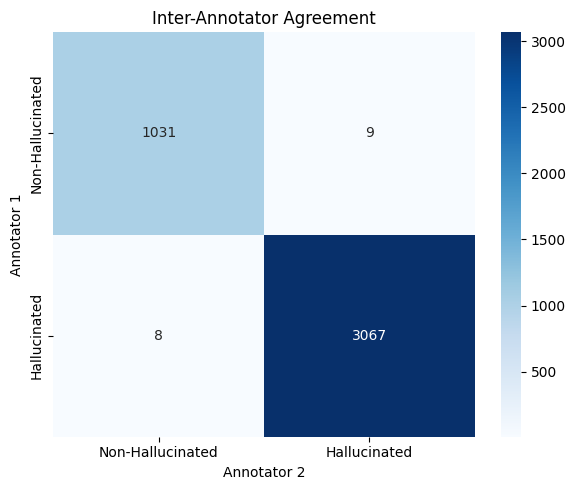

In [ ]:
# ============================================================
# ANNOTATION: AMHARIC HALLUCINATION DETECTION
# CELL 5: JSON CLASS-WISE AGREEMENT ANALYSIS
# ============================================================

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

y1 = matched["label_annotator1"]
y2 = matched["label_annotator2"]

# Confusion matrix
cm = confusion_matrix(y1, y2, labels=[0, 1])

print("CONFUSION MATRIX")
print("Rows = Annotator 1 | Columns = Annotator 2")
print(cm)

print("\nCLASS-WISE AGREEMENT REPORT")
print(classification_report(
    y1,
    y2,
    labels=[0, 1],
    target_names=["Non-Hallucinated", "Hallucinated"],
    zero_division=0
))

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Hallucinated", "Hallucinated"],
    yticklabels=["Non-Hallucinated", "Hallucinated"]
)
plt.xlabel("Annotator 2")
plt.ylabel("Annotator 1")
plt.title("Inter-Annotator Agreement")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# ANNOTATION: AMHARIC HALLUCINATION DETECTION
# CELL 6: EXPORT JSON DISAGREEMENTS FOR EXPERT REVIEW
# ============================================================

import pandas as pd

review = json_disagreements.copy()

review["verified_correct_answer"] = ""
review["final_label"] = ""
review["evidence_source"] = ""
review["adjudication_reason"] = ""

review.to_excel(
    "/content/json_expert_adjudication.xlsx",
    index=False
)

print("Expert adjudication sheet created.")
print("Records requiring review:", len(review))
print("File: json_expert_adjudication.xlsx")

display(review)

Expert adjudication sheet created.
Records requiring review: 17
File: json_expert_adjudication.xlsx


,id,question,answer,label_annotator1,label_annotator2,verified_correct_answer,final_label,evidence_source,adjudication_reason
1,2,ሃይለ ሥላሴ ማን ነበር?,ሃይለ ሥላሴ የናይጄሪያ መሪ ነበር።,0,1,,,,
6,7,በኢትዮጵያ ምን ቋንቋ ይነገራል?,በኢትዮጵያ አማርኛ እና ሌሎች ብዙ ቋንቋዎች ይነገራሉ።,1,0,,,,
9,10,በኢትዮጵያ ሙስሊሞች አሉ ወይ?,አይደለም፣ ኢትዮጵያ ሙሉ በሙሉ ክርስቲያን ናት።,0,1,,,,
11,12,የኢትዮጵያ ገንዘብ ምንድን ነው?,የኢትዮጵያ የገንዘብ አሃድ ናይራ ይባላል።,0,1,,,,
15,16,ኢትዮጵያ በየትኛው አህጉር ላይ ትገኛለች?,ኢትዮጵያ በአውስትራሊያ ትገኛለች።,0,1,,,,
20,21,አፍሪካ ሕብረት ዋና መሥሪያ ቤቱ የት ይገኛል?,አፍሪካ ሕብረት ዋና መሥሪያ ቤቱ በጆሃንስበርግ ይገኛል።,1,0,,,,
25,26,ኢትዮጵያ የባህር በር አላት ወይ?,ኢትዮጵያ የባህር በር የላትም፣ የተዘጋ ሀገር ናት።,0,1,,,,
28,29,በኢትዮጵያ ስንት ብሔረሰቦች አሉ?,በኢትዮጵያ 20 ብሔረሰቦች ብቻ አሉ።,0,1,,,,
30,31,ትግራይ ክልል የኢትዮጵያ ክልል ነው ወይ?,አይደለም፣ ትግራይ ክልል የሱዳን ክልል ነው።,1,0,,,,
41,42,ኢትዮጵያ የቡና መገኛ ናት ወይ?,አይደለም፣ ኢትዮጵያ የቡና መገኛ አይደለችም።,1,0,,,,


In [ ]:
# ============================================================
# AMHARIC HALLUCINATION DETECTION
# CELL 7: LOAD ANNOTATOR 3 JSON
# ============================================================

import json
import pandas as pd

with open("/content/annotation3.json", "r", encoding="utf-8") as f:
    annotation3_json = json.load(f)

ann3 = pd.DataFrame(annotation3_json)

print("Annotator 3 records:", len(ann3))
print("Columns:", ann3.columns.tolist())
print("\nFirst 5 records:")
display(ann3.head())

Annotator 3 records: 4115
Columns: ['id', 'question', 'answer', 'label']

First 5 records:


,id,question,answer,label
0,1,ኢትዮጵያ በየትኛው አህጉር ላይ ትገኛለች?,ኢትዮጵያ በአውስትራሊያ ትገኛለች።,1
1,2,ሃይለ ሥላሴ ማን ነበር?,ሃይለ ሥላሴ የናይጄሪያ መሪ ነበር።,0
2,3,በኢትዮጵያ ሙስሊሞች አሉ ወይ?,አይደለም፣ ኢትዮጵያ ሙሉ በሙሉ ክርስቲያን ናት።,1
3,4,ኢትዮጵያ የገንዘብ አሃድ ምን ይባላል?,ኢትዮጵያ የገንዘብ አሃድ ዶላር ይባላል።,0
4,5,ሃይለ ሥላሴ ማን ነበር?,ሃይለ ሥላሴ የኢትዮጵያ ንጉሠ ነገሥት ነበር።,1


In [86]:
# ============================================================
# AMHARIC HALLUCINATION DETECTION
# CELL 8: MERGE AND VALIDATE THREE ANNOTATORS
# ============================================================

# Convert annotation files into DataFrames
ann1 = pd.DataFrame(annotation1_json)
ann2 = pd.DataFrame(annotation2_json)
ann3 = pd.DataFrame(annotation3_json)

# Keep ID and label only
ann1 = ann1[["id", "label"]].rename(columns={"label": "annotator1"})
ann2 = ann2[["id", "label"]].rename(columns={"label": "annotator2"})
ann3 = ann3[["id", "label"]].rename(columns={"label": "annotator3"})

# Merge by record ID
three_annotators = ann1.merge(ann2, on="id", validate="one_to_one")
three_annotators = three_annotators.merge(
    ann3, on="id", validate="one_to_one"
)

# Validate records and labels
assert len(three_annotators) == 4115
assert three_annotators[["annotator1", "annotator2", "annotator3"]].notna().all().all()
assert three_annotators[["annotator1", "annotator2", "annotator3"]].isin([0, 1]).all().all()

print("Total matched records:", len(three_annotators))
print("Missing labels:", three_annotators.isna().sum().sum())
print("\nThree-annotator label distribution:")
display(three_annotators[["annotator1", "annotator2", "annotator3"]].apply(pd.Series.value_counts).fillna(0).astype(int))

print("\nFirst five merged records:")
display(three_annotators.head())

Total matched records: 4115
Missing labels: 0

Three-annotator label distribution:


,annotator1,annotator2,annotator3
1,3075,3076,3073
0,1040,1039,1042



First five merged records:


,id,annotator1,annotator2,annotator3
0,1,1,1,1
1,2,0,1,0
2,3,1,1,1
3,4,1,1,0
4,5,0,0,1


In [87]:
# ============================================================
# AMHARIC HALLUCINATION DETECTION
# CELL 9: THREE-ANNOTATOR AGREEMENT
# ============================================================

!pip -q install statsmodels

import numpy as np
from statsmodels.stats.inter_rater import fleiss_kappa

# Count annotator votes for each class
vote_counts = np.array([
    [
        (row == 0).sum(),
        (row == 1).sum()
    ]
    for row in three_annotators[
        ["annotator1", "annotator2", "annotator3"]
    ].values
])

# Calculate Fleiss' Kappa
kappa = fleiss_kappa(vote_counts)

# Calculate unanimous and non-unanimous records
unanimous = (
    three_annotators[
        ["annotator1", "annotator2", "annotator3"]
    ].nunique(axis=1) == 1
)

print("THREE-ANNOTATOR AGREEMENT")
print("=" * 45)
print("Total records:", len(three_annotators))
print("Unanimous agreements:", unanimous.sum())
print("Non-unanimous records:", (~unanimous).sum())
print("Unanimous agreement (%):", round(unanimous.mean() * 100, 2))
print("Fleiss' Kappa:", round(kappa, 4))

THREE-ANNOTATOR AGREEMENT
Total records: 4115
Unanimous agreements: 4094
Non-unanimous records: 21
Unanimous agreement (%): 99.49
Fleiss' Kappa: 0.991


In [88]:
# ============================================================
# AMHARIC HALLUCINATION DETECTION
# CELL 10: THREE-ANNOTATOR DISAGREEMENT ANALYSIS
# ============================================================

# Find records without unanimous agreement
disagreements3 = three_annotators[
    three_annotators[
        ["annotator1", "annotator2", "annotator3"]
    ].nunique(axis=1) > 1
].copy()

# Count votes for each class
disagreements3["non_hallucinated_votes"] = (
    disagreements3[["annotator1", "annotator2", "annotator3"]]
    .eq(0).sum(axis=1)
)

disagreements3["hallucinated_votes"] = (
    disagreements3[["annotator1", "annotator2", "annotator3"]]
    .eq(1).sum(axis=1)
)

print("Total disagreement records:", len(disagreements3))
print("\nDisagreement details:")
display(disagreements3.head(20))

Total disagreement records: 21

Disagreement details:


,id,annotator1,annotator2,annotator3,non_hallucinated_votes,hallucinated_votes
1,2,0,1,0,2,1
3,4,1,1,0,1,2
4,5,0,0,1,2,1
5,6,1,1,0,1,2
6,7,1,0,0,2,1
7,8,1,1,0,1,2
9,10,0,1,1,1,2
11,12,0,1,1,1,2
15,16,0,1,1,1,2
20,21,1,0,0,2,1


In [89]:
# ============================================================
# AMHARIC HALLUCINATION DETECTION
# CELL 11: EXPORT EXPERT ADJUDICATION FILE
# ============================================================

# Add question and answer text from the original dataset
original = pd.DataFrame(annotation1_json)[["id", "question", "answer"]]

review_sheet = disagreements3.merge(
    original, on="id", how="left", validate="one_to_one"
)

# Add expert review columns
review_sheet["expert_final_label"] = ""
review_sheet["evidence_source"] = ""
review_sheet["adjudication_reason"] = ""

# Arrange columns
review_sheet = review_sheet[
    [
        "id", "question", "answer",
        "annotator1", "annotator2", "annotator3",
        "non_hallucinated_votes", "hallucinated_votes",
        "expert_final_label", "evidence_source",
        "adjudication_reason"
    ]
]

output_file = "/content/three_annotator_expert_review.xlsx"
review_sheet.to_excel(output_file, index=False)

print("Expert review file created:", output_file)
print("Records requiring review:", len(review_sheet))

Expert review file created: /content/three_annotator_expert_review.xlsx
Records requiring review: 21


In [90]:
# ============================================================
# AMHARIC HALLUCINATION DETECTION
# CELL 12: EXPORT ANNOTATION AGREEMENT RESULTS
# ============================================================

import pandas as pd

# Agreement summary
agreement_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Number of annotators",
        "Unanimous agreements",
        "Non-unanimous records",
        "Unanimous agreement (%)",
        "Fleiss' Kappa"
    ],
    "Value": [
        len(three_annotators),
        3,
        int(unanimous.sum()),
        int((~unanimous).sum()),
        round(unanimous.mean() * 100, 2),
        round(kappa, 4)
    ]
})

# Save results in one Excel workbook
results_file = "/content/three_annotator_agreement_results.xlsx"

with pd.ExcelWriter(results_file) as writer:
    agreement_summary.to_excel(
        writer, sheet_name="Agreement Summary", index=False
    )
    three_annotators.to_excel(
        writer, sheet_name="All Annotations", index=False
    )
    disagreements3.to_excel(
        writer, sheet_name="Disagreements", index=False
    )

print("Results saved:", results_file)
display(agreement_summary)

Results saved: /content/three_annotator_agreement_results.xlsx


,Metric,Value
0,Total records,4115.000
1,Number of annotators,3.000
2,Unanimous agreements,4094.000
3,Non-unanimous records,21.000
4,Unanimous agreement (%),99.490
5,Fleiss' Kappa,0.991
